# Credit Card Transactions Fraud Detection

About 1 in 200 card payments is fraud, and a fraud team can only check so many alerts a day. Here I catch fraud with features built only from the past, and test honestly in time: train on January 2019 to June 2020, then test once on the six months after.

**Data** → [Credit Card Transactions Fraud Detection](https://www.kaggle.com/datasets/kartik2112/fraud-detection) · 1.85 million simulated transactions · ~1,000 cards · about 0.5% fraud. The data is simulated and its fraud patterns are regular, so a real fraud system would score far lower; the value here is the method.

**Parts**
1. **Data understanding** → data dictionary, data health, imbalance, how train and test relate in time
2. **EDA** → fraud patterns, Mann-Whitney U and chi-square tests with effect sizes, correlation
3. **Feature engineering** → past-only card history features, brute-force leakage check, time-based split
4. **Modeling** → baselines, ensembles, feature ablation, imbalance strategies, learning curve, Optuna
5. **Evaluation & explainability** → cost-based threshold, test results, calibration, SHAP, error analysis, stability

<!-- objective -->
## Aim and objectives

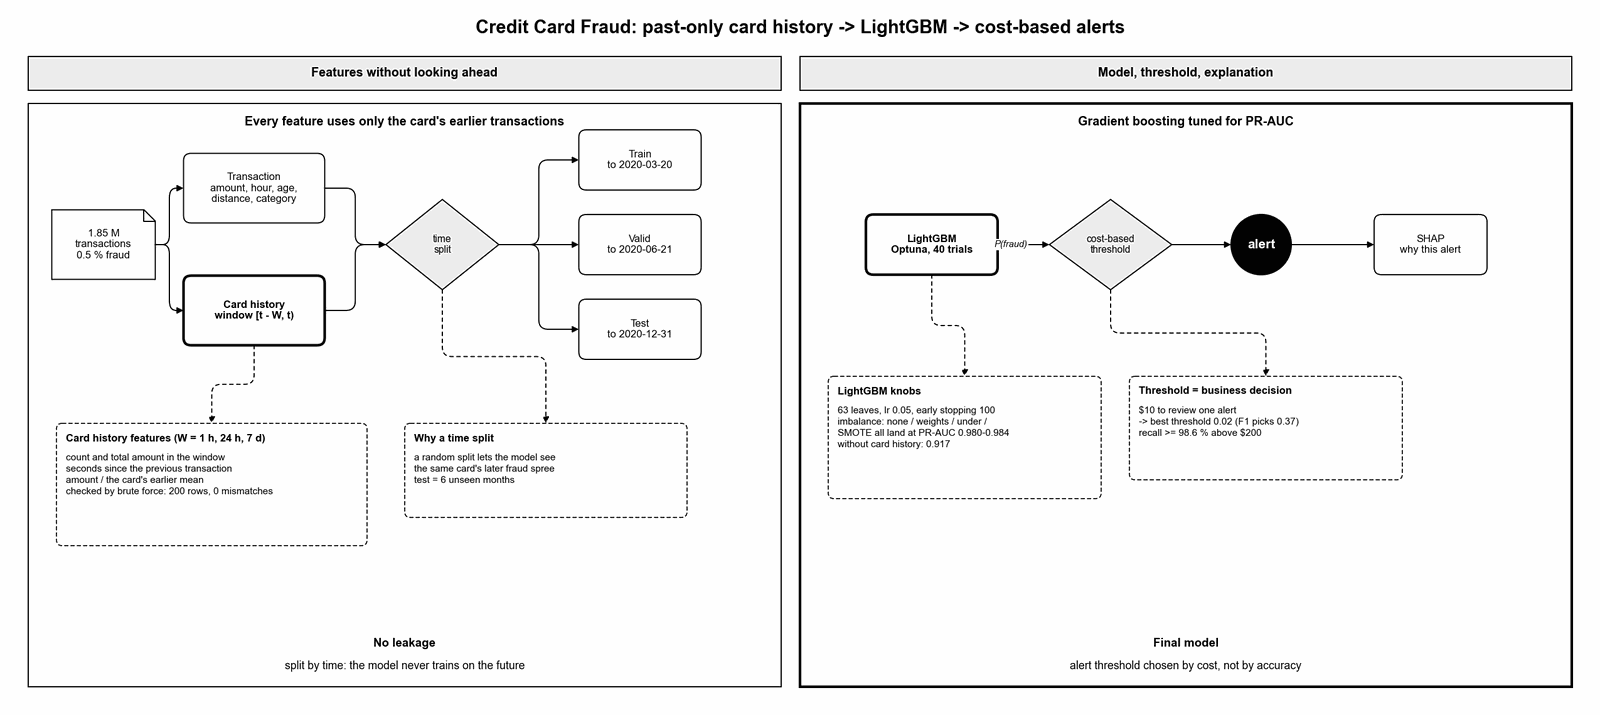

**Aim** → rank every card payment by fraud risk using only what the bank knew *at that moment*, then pick the alert line from the cost of a review, not from accuracy.

**Objectives**
1. Get to know the raw data: what each column means, how clean it is, how rare fraud is, and how train and test sit in time
2. Find which signals separate fraud from normal payments, and back each one with a statistical test
3. Build features from each card's past only (no peeking at the future), and check that by brute force
4. Compare models, imbalance fixes and feature sets on a validation period, then tune the best one
5. Pick the alert threshold by dollar cost, test once on six future months, and explain the decisions with SHAP

**Why it matters** → most fraud-model mistakes happen *before* the model: leakage, a shuffled split, the wrong score. So every choice here is made on validation data, and the test period is touched once, at the very end.

**Where it could help** → an alert queue: the riskiest payments go to an analyst (or trigger an SMS check) first; moving the threshold trades missed fraud against analyst workload. An alert is only useful if the analyst can also see *why* it was raised, so the last part explains single decisions.

# Setup

Every setting lives in the next cell, and the helper functions every part uses come right after it. Run once; nothing is written to disk unless you set `SAVE_FIGURES = True`.

In [ ]:
"""Optional · Add Input → dataset kartik2112/fraud-detection, then Run All.

[1/3] RANDOM_STATE: random seed
    Default = 42
[2/3] VALID_START: first day of the validation period (the last ~3 months of fraudTrain.csv)
    Default = '2020-03-21'
[3/3] SAVE_FIGURES: also write every chart as a PNG into /kaggle/working/figures
    Default = False
"""
from pathlib import Path

RANDOM_STATE  = 42
VALID_START   = '2020-03-21'
SAVE_FIGURES  = False

TARGET        = 'is_fraud'
ROOT          = Path('/kaggle/working')
RAW_FILE      = next(Path('/kaggle/input').rglob('fraudTrain.csv'), None)
assert RAW_FILE, '💀 fraudTrain.csv not found → Add Input → dataset kartik2112/fraud-detection'
RAW_DIR       = RAW_FILE.parent
FIGURES_DIR   = ROOT / 'figures'
COLORS        = {0: '#6b7280', 1: '#dc2626'}
LABELS        = {0: 'Legit', 1: 'Fraud'}

if SAVE_FIGURES:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import average_precision_score, confusion_matrix, f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve

In [ ]:
RENAME = {
    "trans_date_trans_time": "trans_time",
    "cc_num": "card_id",
    "amt": "amount",
    "trans_num": "trans_id",
}

CATEGORICAL = ["merchant", "category", "gender", "city", "state", "job"]


def load_raw(split: str = "train") -> pd.DataFrame:
    """Load fraudTrain.csv (split='train') or fraudTest.csv (split='test').

    - drops the CSV index column
    - renames a few columns to readable names
    - parses datetimes, stores low-cardinality text as `category` dtype
    """
    fname = {"train": "fraudTrain.csv", "test": "fraudTest.csv"}[split]
    df = pd.read_csv(RAW_DIR / fname, index_col=0)
    df = df.rename(columns=RENAME)
    df["trans_time"] = pd.to_datetime(df["trans_time"])
    df["dob"] = pd.to_datetime(df["dob"])
    df["card_id"] = df["card_id"].astype("int64")
    for col in CATEGORICAL:
        df[col] = df[col].astype("category")
    df["is_fraud"] = df["is_fraud"].astype("int8")
    df["source"] = split
    return df


def load_all() -> pd.DataFrame:
    """Train + test stacked and sorted by time (needed for causal per-card features)."""
    df = pd.concat([load_raw("train"), load_raw("test")], ignore_index=True)
    for col in CATEGORICAL:
        df[col] = df[col].astype("category")
    return df.sort_values("trans_time", kind="stable").reset_index(drop=True)

In [ ]:
def score(y_true, proba, threshold: float = 0.5, name: str = "model") -> dict:
    pred = (proba >= threshold).astype(int)
    return {
        "model": name,
        "pr_auc": average_precision_score(y_true, proba),
        "roc_auc": roc_auc_score(y_true, proba),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "f1": f1_score(y_true, pred),
        "threshold": threshold,
    }


def recall_at_precision(y_true, proba, min_precision: float = 0.9) -> float:
    p, r, _ = precision_recall_curve(y_true, proba)
    ok = p >= min_precision
    return float(r[ok].max()) if ok.any() else 0.0


def fraud_cost(y_true, proba, amount, threshold, review_cost: float = 10.0) -> float:
    """Business cost in $: every alert costs `review_cost` to investigate,
    every missed fraud costs its transaction amount."""
    pred = proba >= threshold
    y_true = np.asarray(y_true).astype(bool)
    missed = (~pred & y_true)
    return float(pred.sum() * review_cost + np.asarray(amount)[missed].sum())


def best_cost_threshold(y_true, proba, amount, review_cost: float = 10.0, grid=None):
    grid = np.linspace(0.01, 0.99, 99) if grid is None else grid
    costs = np.array([fraud_cost(y_true, proba, amount, t, review_cost) for t in grid])
    return float(grid[costs.argmin()]), pd.DataFrame({"threshold": grid, "cost": costs})


def best_f1_threshold(y_true, proba):
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    return float(t[np.nanargmax(f1[:-1])])


def plot_pr_roc(results: dict, y_true, ax=None):
    """results: {name: proba}. Draws PR and ROC curves side by side."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5)) if ax is None else (None, ax)
    base = np.mean(y_true)
    for name, proba in results.items():
        p, r, _ = precision_recall_curve(y_true, proba)
        axes[0].plot(r, p, label=f"{name} (AP={average_precision_score(y_true, proba):.3f})")
        fpr, tpr, _ = roc_curve(y_true, proba)
        axes[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_true, proba):.3f})")
    axes[0].axhline(base, ls="--", c="grey", lw=1, label=f"random ({base:.4f})")
    axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall")
    axes[1].plot([0, 1], [0, 1], ls="--", c="grey", lw=1)
    axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC")
    for a in axes:
        a.legend(fontsize=9, loc="best")
    return fig


def plot_confusion(y_true, proba, threshold, ax=None, title=None):
    cm = confusion_matrix(y_true, proba >= threshold)
    ax = ax or plt.subplots(figsize=(5, 4))[1]
    ax.imshow(cm, cmap="Greys")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,}", ha="center", va="center",
                color="white" if v > cm.max() / 2 else COLORS[1], fontsize=13, weight="bold")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Legit", "Fraud"], yticklabels=["Legit", "Fraud"],
           xlabel="Predicted", ylabel="Actual", title=title or f"Confusion matrix @ {threshold:.2f}")
    return ax

In [ ]:
EARTH_RADIUS_KM = 6371.0


def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance between two points (vectorised)."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(a))


def add_transaction_features(df: pd.DataFrame) -> pd.DataFrame:
    """Features computable from a single row."""
    out = df.copy()
    t = out["trans_time"]
    out["hour"] = t.dt.hour.astype("int8")
    out["day_of_week"] = t.dt.dayofweek.astype("int8")
    out["is_night"] = out["hour"].isin([22, 23, 0, 1, 2, 3]).astype("int8")
    out["age"] = ((t - out["dob"]).dt.days / 365.25).astype("float32")
    out["log_amount"] = np.log1p(out["amount"]).astype("float32")
    out["log_city_pop"] = np.log1p(out["city_pop"]).astype("float32")
    out["distance_km"] = haversine_km(out["lat"], out["long"], out["merch_lat"], out["merch_long"]).astype("float32")
    out["is_male"] = (out["gender"] == "M").astype("int8")
    return out


def add_card_history_features(df: pd.DataFrame, windows=("1h", "24h", "7d")) -> pd.DataFrame:
    """Per-card behavioural features that look only BACKWARDS in time.

    For each window W:
      card_txn_count_W  - number of the card's previous transactions in the last W
      card_amount_sum_W - total amount of those transactions
    Plus:
      secs_since_prev_txn - seconds since the card's previous transaction
      amount_vs_card_mean - amount / mean of the card's previous amounts (expanding)
      card_txn_index      - how many transactions the card has made before this one
    """
    out = df.sort_values(["card_id", "trans_time"], kind="stable").copy()
    g = out.groupby("card_id", sort=False, observed=True)

    out["secs_since_prev_txn"] = g["trans_time"].diff().dt.total_seconds().astype("float32")
    out["card_txn_index"] = g.cumcount().astype("int32")

    prev_mean = g["amount"].transform(lambda s: s.shift().expanding().mean())
    out["amount_vs_card_mean"] = (out["amount"] / prev_mean).astype("float32")

    indexed = out.set_index("trans_time")[["card_id", "amount"]]
    for w in windows:
        roll = indexed.groupby("card_id", sort=False)["amount"].rolling(w, closed="left")
        out[f"card_txn_count_{w}"] = roll.count().fillna(0).to_numpy().astype("float32")
        out[f"card_amount_sum_{w}"] = roll.sum().fillna(0).to_numpy().astype("float32")

    return out.sort_values("trans_time", kind="stable").reset_index(drop=True)


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    return add_card_history_features(add_transaction_features(df))


NUMERIC_FEATURES = [
    "amount", "log_amount", "hour", "day_of_week", "is_night", "age", "is_male",
    "log_city_pop", "distance_km",
    "secs_since_prev_txn", "card_txn_index", "amount_vs_card_mean",
    "card_txn_count_1h", "card_amount_sum_1h",
    "card_txn_count_24h", "card_amount_sum_24h",
    "card_txn_count_7d", "card_amount_sum_7d",
]
CATEGORICAL_FEATURES = ["category"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

In [ ]:
CMAP = "Greys"


def set_style():
    """Grey 'darkgrid' look (same as my Ensemble / Tuberculosis notebooks); red is reserved for fraud."""
    sns.set_style("darkgrid")
    sns.set_palette("gray", 8)
    sns.set_context("notebook", font_scale=1.05)
    plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})


def savefig(fig, name):
    """Write the chart to FIGURES_DIR/<name>.png when SAVE_FIGURES is on."""
    if SAVE_FIGURES:
        fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=110)

# Part [1/5] Data Understanding

**What I'm trying to do** → get to know the raw data before any model. The answers decide which columns I use, which score I trust and how I split the data.

The data is simulated with [Sparkov](https://github.com/namebrandon/Sparkov_Data_Generation): ~1,000 customers × ~800 merchants, **2019-01-01 → 2020-12-31**.

**Outlines**
1. Load data
2. Data dictionary
3. Data health
    - 3.1 Missing values & duplicates
    - 3.2 Descriptive statistics
    - 3.3 Memory usage
4. Target imbalance
5. Train vs test in time
6. Entities: cards and customers
7. Summary & decisions

In [ ]:
SPLITS = ["train", "test"]
NUMERIC_COLS = ["amount", "city_pop", "lat", "long", "merch_lat", "merch_long"]
PERSON_KEY = ["first", "last", "dob"]
MONTH_FREQ = "MS"
SPLIT_COLORS = {"train": "#4b5563", "test": "#9ca3af"}

set_style()
pd.set_option("display.max_columns", 50)

# [1/7] Load data

**Aim** → read both CSV files with the right types: dates as dates, text as `category` (each word stored once, small codes in the rows).

In [ ]:
train = load_raw("train")
test = load_raw("test")

In [ ]:
print(f"train: {train.shape}")
print(f"test : {test.shape}")
train.head()

# [2/7] Data dictionary

**Aim** → find out what each column means, and whether I can use it as a feature.

| Column | Meaning | Use as feature? |
|---|---|---|
| `trans_time` | Timestamp of the transaction | → hour, day of week, card history |
| `card_id` | Credit card number (renamed from `cc_num`) | ✗ identifier, only for grouping |
| `merchant` | Merchant name | ✗ ~700 simulated names |
| `category` | Spending category (14 values) | ✓ |
| `amount` | Transaction amount in USD | ✓ |
| `first`, `last`, `street` | Card holder name / address | ✗ personal identifiers |
| `gender` | Card holder gender | ✓ binary |
| `city`, `state`, `zip` | Card holder location | (!) too many values → summarised by `city_pop` / distance |
| `lat`, `long` | Card holder coordinates | → distance to merchant |
| `city_pop` | Population of the holder's city | ✓ (log) |
| `job` | Card holder job (~500 values) | ✗ too many values |
| `dob` | Date of birth | → age at transaction |
| `trans_id` | Unique transaction id | ✗ identifier |
| `unix_time` | Same moment as `trans_time` in seconds | ✗ duplicate information |
| `merch_lat`, `merch_long` | Merchant coordinates | → distance to merchant |
| `is_fraud` | **Target** (1 = fraud) | target |

In [ ]:
dictionary = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "n_unique": train.nunique(),
    "missing": train.isna().sum(),
    "example": train.iloc[0],
})

In [ ]:
dictionary

# [3/7] Data health

**Aim** → check if anything needs cleaning before I build on it.

## 3.1 Missing values & duplicates
**Question:** any missing cells, duplicate rows, duplicate ids, or impossible amounts (zero or negative)?

In [ ]:
health = pd.DataFrame({
    "rows": [len(train), len(test)],
    "missing_cells": [train.isna().sum().sum(), test.isna().sum().sum()],
    "duplicate_rows": [train.drop(columns="source").duplicated().sum(),
                       test.drop(columns="source").duplicated().sum()],
    "duplicate_trans_id": [train.trans_id.duplicated().sum(), test.trans_id.duplicated().sum()],
    "non_positive_amount": [(train.amount <= 0).sum(), (test.amount <= 0).sum()],
}, index=SPLITS)

In [ ]:
health

**Answer:** nothing to clean → 0 missing values, 0 duplicates, no zero or negative amounts. The real work is **feature engineering** and **handling the imbalance**.

## 3.2 Descriptive statistics
**Question:** what ranges do the numeric columns have, and how lopsided are they?

**Skewness in one line** → a number that says how lopsided a distribution is: 0 = both sides look the same, big and positive = a long tail of rare, huge values on the right.

**How, in 3 steps**
1. Turn every value into "how many standard deviations from the mean" (a z-score)
2. Cube it → big distances stay big and keep their sign, small ones almost vanish
3. Average → if a long right tail is there, it wins, so the result is positive

$$\text{skew} = \frac{1}{n}\sum_{i=1}^{n}\left(\frac{x_i-\bar{x}}{s}\right)^3$$
- $x_i$ → one value (e.g. one amount), $n$ → number of values
- $\bar{x}$ → mean, $s$ → standard deviation (the typical distance from the mean)
- In short → 0 = symmetric, above 1 = strongly right-skewed: most values small, a few very big. Taking the log pulls that tail in

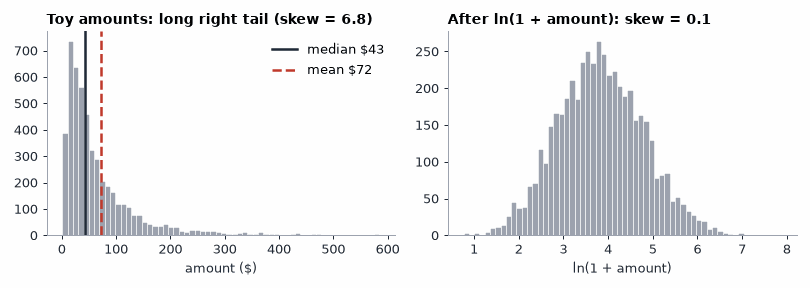

The picture uses toy amounts.

In [ ]:
desc = train[NUMERIC_COLS].describe().T
desc["skew"] = train[NUMERIC_COLS].skew()

In [ ]:
desc.round(2)

**Answer:** `amount` is extremely right-skewed (median ≈ \$47, max ≈ \$28,949, skew ≫ 1), and so is `city_pop` → I look at and use both on a **log scale**.

## 3.3 Memory usage
**Aim** → make sure the full data fits easily in RAM (text stored as `category`).

In [ ]:
memory_mb = pd.Series({name: d.memory_usage(deep=True).sum() / 2**20
                       for name, d in zip(SPLITS, [train, test])}, name="MB")

In [ ]:
memory_mb.round(0)

# [4/7] Target imbalance

**Clue** → the data is clean ([3/7]), so the hard part must be somewhere else. The dataset says fraud is rare.

**Question** → how rare, exactly? The answer decides which score I can trust.

**Fraud rate in one line** → count the frauds and divide by all transactions.

$$\text{fraud rate} = \frac{\#\,\text{fraud}}{\#\,\text{transactions}}$$
- $\#\,\text{fraud}$ → transactions with `is_fraud = 1`
- $\#\,\text{transactions}$ → all transactions in the split
- In short → the share of payments that are fraud: 5 frauds in 1,000 payments = 0.5%

In [ ]:
imbalance = pd.DataFrame({
    "transactions": [len(train), len(test)],
    "frauds": [train[TARGET].sum(), test[TARGET].sum()],
}, index=SPLITS)
imbalance["fraud_rate_%"] = imbalance.frauds / imbalance.transactions * 100
imbalance["legit_per_fraud"] = imbalance.transactions / imbalance.frauds

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, d) in zip(axes, zip(SPLITS, [train, test])):
    counts = d[TARGET].value_counts().sort_index()
    ax.bar([LABELS[i] for i in counts.index], counts.values, color=[COLORS[i] for i in counts.index])
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v:,}\n({v / len(d):.2%})", ha="center", va="bottom")
    ax.set(title=f"{name}: class balance", ylabel="transactions", ylim=(0, counts.max() * 1.2))
savefig(fig, "01_class_balance")
plt.close(fig)

In [ ]:
imbalance.round(3)

In [ ]:
fig

**Answer:** only **~0.5 %** of transactions are fraud (1 in 173 in train, 1 in 259 in test).

Notice the two files don't share one rate: that gap is the lead for [5/7].

**Why it matters**
- **Accuracy is meaningless** → always saying "legit" already scores 99.4 %
- So I score with **PR-AUC**, **precision / recall** and a **dollar cost** (explained in Part 4 [2/11] and Part 5 [2/11])
- Imbalance fixes (class weights, undersampling, SMOTE) are compared in Part 4

# [5/7] Train vs test in time

**Something odd** → the two files have different fraud rates: 1 in 173 in `fraudTrain`, 1 in 259 in `fraudTest`.

**I suspect** → they are not two random halves of one pile, but two periods, one after the other, and fraud changes over time.

**Question** → how do the two files sit in time? The answer decides how I validate.

**Let's break it down** → 1) where does each file start and end? 2) volume and fraud rate per month

In [ ]:
both = pd.concat([train, test])
periods = both.groupby("source").trans_time.agg(["min", "max"])
monthly = (both.set_index("trans_time")
           .groupby([pd.Grouper(freq=MONTH_FREQ), "source"])[TARGET]
           .agg(["size", "mean"]).reset_index())

fig, ax1 = plt.subplots(figsize=(14, 4.5))
for src, c in SPLIT_COLORS.items():
    m = monthly[monthly.source == src]
    ax1.bar(m.trans_time, m["size"], width=25, color=c, alpha=0.8, label=f"{src} transactions")
ax2 = ax1.twinx()
ax2.plot(monthly.trans_time, monthly["mean"] * 100, color=COLORS[1], marker="o", label="fraud rate %")
ax1.set(ylabel="transactions / month", title="Volume and fraud rate per month")
ax2.set_ylabel("fraud rate (%)")
ax2.grid(False)
fig.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08), frameon=False)
savefig(fig, "01_timeline")
plt.close(fig)

In [ ]:
periods

In [ ]:
fig

**Answer:** my suspicion was right.
- `fraudTest` starts **the exact second** `fraudTrain` ends → the official split is a **time split**
- Volume is seasonal (December peaks) and the fraud rate drifts (train 0.58 % vs test 0.39 %)

**What I do with it** → never shuffle. Train on the past, validate on the most recent part of `fraudTrain` (from **2020-03-21**), and touch `fraudTest` **once**, at the very end. A random split would leak future patterns into training and make the scores look better than they are (picture in Part 3 [1/9]).

# [6/7] Entities: cards and customers

**I'm curious** → about 1,000 cards make 1.85 million payments. Is fraud spread thinly over many cards, or packed onto a few?

**Let's break it down** → 1) count cards and customers 2) count transactions and frauds per card

In [ ]:
per_card = both.groupby("card_id", observed=True).agg(n_txn=("trans_id", "size"), n_fraud=(TARGET, "sum"))
cards_per_person = both.groupby(PERSON_KEY, observed=True).card_id.nunique()

In [ ]:
print(f"cards                 : {len(per_card):,}")
print(f"cards with ≥ 1 fraud  : {(per_card.n_fraud > 0).sum():,} ({(per_card.n_fraud > 0).mean():.1%})")
print(f"transactions per card : median {per_card.n_txn.median():.0f}, max {per_card.n_txn.max():,}")
print(f"frauds per fraud card : median {per_card.loc[per_card.n_fraud > 0, 'n_fraud'].median():.0f}, "
      f"max {per_card.n_fraud.max()}")
print("cards per person      :", cards_per_person.value_counts().to_dict())

**Answer:**
- Every person holds exactly **one card** → "number of cards per person" (used in my old version) tells nothing
- Almost every card (97.7 %) is hit, typically by **~10 fraudulent transactions** → fraud comes in **bursts on a card**. So per-card history features (Part 3) are the most promising idea

# [7/7] Summary & decisions

**Aim** → turn what I found into decisions for the next parts.

| Finding | Decision |
|---|---|
| Clean data, no missing / duplicates | no cleaning step needed |
| 0.5 % fraud | PR-AUC + cost metrics; compare imbalance strategies |
| Official split is in time, fraud rate drifts | time-based train / valid / test |
| Fraud happens in bursts per card | build leak-free card history features |
| Identifiers & text with too many values | drop, or summarise (distance, city_pop) |

# Part [2/5] Exploratory Data Analysis

**Clue** → Part 1 left three leads: `amount` is extremely lopsided (median ≈ \$47, max ≈ \$28,949), only ~0.5 % of payments are fraud, and fraud comes in **bursts of ~10 on one card**.

**Question** → which signals really separate fraud from normal payments?

**Let's break it down** → follow each lead with a picture, check every picture with a statistical test, and keep what survives as features for Part 3.

(!) EDA uses **`fraudTrain` only**. The test period stays unseen until the final evaluation, otherwise my choices would be tuned to the test set.

**Outlines**
1. Amount
2. Spending category
3. Time cycles: hour & day of week
4. Card holder: age, gender, city size
5. Geography: distance & state
6. Card behaviour: fraud bursts
7. Statistical tests
    - 7.1 Numeric features → Mann-Whitney U
    - 7.2 Categorical features → χ² & Cramér's V
8. Correlation
9. Summary

In [ ]:
from scipy import stats

PALETTE = {LABELS[k]: v for k, v in COLORS.items()}
AMOUNT_BINS = [0, 10, 50, 100, 200, 300, 500, 800, 1000, 1500, 30000]
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
BURST_WINDOW = (pd.Timedelta("7D"), pd.Timedelta("4D"))
NUMERIC_TESTED = ["amount", "hour", "is_night", "age", "log_city_pop", "distance_km", "secs_since_prev_txn",
                  "card_txn_count_1h", "card_txn_count_24h", "card_txn_count_7d", "card_amount_sum_24h",
                  "amount_vs_card_mean", "card_txn_index"]
CATEGORICAL_TESTED = ["category", "gender", "state", "day_of_week", "job", "merchant"]

set_style()

In [ ]:
df = build_features(load_raw("train"))
df["label"] = df[TARGET].map(LABELS)
fraud, legit = df[df[TARGET] == 1], df[df[TARGET] == 0]
BASE_RATE = df[TARGET].mean()

In [ ]:
print(f"{len(df):,} transactions, fraud rate {BASE_RATE:.3%}")

In [ ]:
def fraud_rate_bar(col, ax, order=None, rotate=0):
    """Bar = fraud rate per value of `col`; dashed line = overall fraud rate."""
    rate = df.groupby(col, observed=True)[TARGET].mean().mul(100)
    rate = rate.reindex(order) if order is not None else rate.sort_values(ascending=False)
    ax.bar(rate.index.astype(str), rate.values, color=COLORS[1], alpha=0.85)
    ax.axhline(BASE_RATE * 100, ls="--", c="black", lw=1, label=f"overall {BASE_RATE:.2%}")
    ax.set(ylabel="fraud rate (%)", title=f"Fraud rate by {col}")
    ax.tick_params(axis="x", rotation=rotate)
    ax.legend()
    return rate

# [1/9] Amount

**Clue** → `amount` is the most lopsided column in Part 1: median ≈ \$47, max ≈ \$28,949.

**I suspect** → fraudsters spend differently, and the long tail of huge payments is where the fraud is.

**Question** → do fraud amounts differ from normal ones, and where?

**Let's break it down** → 1) compare the two amount distributions on a log scale 2) fraud rate per amount band

**Fraud rate per band** → cut the amounts into bands (\$0–10, \$10–50, …) and compute the fraud rate inside each band.

$$\text{fraud rate}_{b} = \frac{\#\,\text{fraud in band } b}{\#\,\text{transactions in band } b}$$
- $b$ → one amount band, e.g. \$800–1,000
- In short → out of all payments of that size, the share that is fraud

In [ ]:
amount_summary = df.groupby("label")["amount"].describe()
money = df.groupby("label")["amount"].sum()
df["amount_band"] = pd.cut(df["amount"], AMOUNT_BINS)
band_rate = df.groupby("amount_band", observed=True)[TARGET].mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
sns.histplot(data=df, x="amount", hue="label", log_scale=True, bins=80, stat="density",
             common_norm=False, element="step", palette=PALETTE, ax=axes[0])
axes[0].set_title("Amount distribution (log scale)")
axes[1].bar(money.index, money.values / 1e6, color=[PALETTE[i] for i in money.index])
for i, v in enumerate(money.values):
    axes[1].text(i, v / 1e6, f"${v / 1e6:.1f}M\n({v / money.sum():.1%})", ha="center", va="bottom")
axes[1].set(title="Total money moved", ylabel="USD (millions)", ylim=(0, money.max() / 1e6 * 1.2))
axes[2].bar(band_rate.index.astype(str), band_rate.values, color=COLORS[1])
axes[2].set(title="Fraud rate by amount band", ylabel="fraud rate (%)")
axes[2].tick_params(axis="x", rotation=45)
savefig(fig, "02_amount")
plt.close(fig)

In [ ]:
amount_summary.round(1)

In [ ]:
fig

**Answer:** yes, very differently, but I was wrong about the tail: the huge payments are normal ones. Fraud sits in bands of its own.
- Fraud amounts form **three clusters**: small "card testing" charges (≈ \$10–25, a tiny buy to check the card works), ≈ \$300 and ≈ \$800–1,100. Normal spending sits mostly below \$100. The largest fraud is only \$1,376
- Fraud is **0.6 % of transactions but 4.4 % of the money** → catching it matters financially
- In the **\$800–1,000 band more than half of all transactions are fraud**; below \$200 fraud is almost absent

My old version removed amount "outliers" with a z-test, which threw away exactly the fraud cases. I keep every row.

# [2/9] Spending category

**I'm curious** → fraud picks clear amount bands. Does it also pick certain kinds of shops?

In [ ]:
mix = pd.crosstab(df["category"], df["label"], normalize="columns").mul(100)
mix["fraud_minus_legit_pp"] = mix["Fraud"] - mix["Legit"]
cat_order = df.groupby("category", observed=True)[TARGET].mean().sort_values(ascending=False).index

fig, axes = plt.subplots(2, 1, figsize=(15, 10))
fraud_rate_bar("category", axes[0], rotate=45)
sns.boxplot(data=df, x="category", y="amount", hue="label", order=cat_order, palette=PALETTE,
            showfliers=False, ax=axes[1])
axes[1].set(yscale="log", title="Amount per category: fraud vs legit (log scale)")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
savefig(fig, "02_category")
plt.close(fig)

In [ ]:
mix.sort_values("fraud_minus_legit_pp", ascending=False).round(2)

In [ ]:
fig

**Answer:** yes.
- `shopping_net`, `grocery_pos` and `misc_net` are much more common in fraud (+15, +14 and +7 percentage points)
- home, kids/pets, food and health are rarely targeted
- Inside every category, fraud amounts are far higher than normal ones → **category × amount** is a strong pattern (an \$800 grocery bill is very unusual)

# [3/9] Time cycles: hour & day of week

**Clue** → fraud starts with tiny "card testing" charges, a sign that someone other than the owner is trying the card, and it leans towards `shopping_net` and `misc_net`, where no one sees the buyer.

**I suspect** → a stolen card is used while the owner sleeps and won't notice.

**Question** → does fraud happen at certain hours of the day, or on certain days?

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
hour_rate = fraud_rate_bar("hour", axes[0], order=range(24))
day_rate = fraud_rate_bar("day_of_week", axes[1], order=range(7))
axes[1].set_xticks(range(7), DAYS)
savefig(fig, "02_time_cycles")
plt.close(fig)

In [ ]:
pd.DataFrame({"night 22-23h": [hour_rate.loc[[22, 23]].mean()],
              "night 0-3h": [hour_rate.loc[0:3].mean()],
              "day 4-21h": [hour_rate.loc[4:21].mean()]}, index=["fraud rate %"]).round(2)

In [ ]:
fig

**Answer:** yes, the hunch held: **hour is the strongest time signal**.

| Time | Fraud rate |
|---|---|
| 22:00–23:59 | ≈ 2.9 % |
| 00:00–03:59 | ≈ 1.5 % |
| during the day | ≈ 0.1 % |

That's **15–30× higher at night** → I add an `is_night` flag. Day of week shows only mild differences (Wed–Fri slightly higher).

# [4/9] Card holder: age, gender, city size

**Question** → so far every signal describes the *payment*. Does the *person* matter too: are some customers more often victims?

**Let's break it down** → fraud rate by age, by gender and by city size

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.kdeplot(data=df, x="age", hue="label", common_norm=False, fill=True, palette=PALETTE, ax=axes[0])
axes[0].set_title("Age at transaction")
gender_rate = fraud_rate_bar("gender", axes[1])
sns.kdeplot(data=df, x="log_city_pop", hue="label", common_norm=False, fill=True, palette=PALETTE, ax=axes[2])
axes[2].set_title("City population (log)")
savefig(fig, "02_holder")
plt.close(fig)

In [ ]:
gender_rate.round(3)

In [ ]:
fig

**Answer:** only weakly. Older holders (60+) are somewhat more often victims; gender and city size show small differences. Weak features on their own.

# [5/9] Geography: distance & state

**I suspect** → a stolen card number is used far from home, so fraud payments should happen further from the holder's address.

**Question** → does the distance between holder and merchant matter, or the state?

**Haversine distance in one line** → the distance between two places on Earth measured along its curved surface (like a plane's route), not a straight tunnel through the ground.

**How, in 3 steps**
1. Turn the latitude and longitude of the customer and of the merchant into radians (angles)
2. Work out the angle between the two places, seen from the centre of the Earth
3. Multiply that angle by the Earth's radius → length of the arc in km

$$d = 2R\arcsin\sqrt{\sin^2\frac{\Delta\varphi}{2} + \cos\varphi_1\cos\varphi_2\sin^2\frac{\Delta\lambda}{2}}$$
- $\varphi_1, \varphi_2$ → latitudes (north-south) of customer and merchant, $\Delta\varphi$ → their difference
- $\Delta\lambda$ → difference in longitude (east-west)
- $R = 6371$ km → Earth's radius
- $2\arcsin\sqrt{\cdots}$ → the angle from step 2
- In short → angle between the two places × Earth's radius = distance along the surface

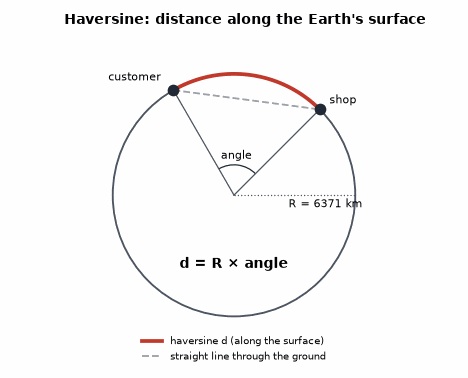

In [ ]:
state_stats = (df.groupby("state", observed=True)[TARGET].agg(["size", "sum", "mean"])
               .sort_values("mean", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
sns.kdeplot(data=df, x="distance_km", hue="label", common_norm=False, fill=True, palette=PALETTE, ax=axes[0])
axes[0].set_title("Distance card holder → merchant (km)")
fraud_rate_bar("state", axes[1], rotate=90)
savefig(fig, "02_geography")
plt.close(fig)

In [ ]:
state_stats.head(8)

In [ ]:
fig

**Answer:** no, I was wrong.
- Distance to the merchant has **no signal**: the simulator places merchants at random around the holder (real data would likely differ). I keep it so the model can confirm this
- The highest state fraud rates come from states with very few transactions (DE: 9 transactions, all fraud) → noise, not signal. **State is not used as a feature**

# [6/9] Card behaviour: fraud bursts

**Clue** → Part 1 found ~10 frauds per hit card, and [1/9] found tiny "testing" charges before the big ones. Neither the person ([4/9]) nor the place ([5/9]) explained much.

**I suspect** → the card itself behaves differently while it is being emptied: payments come faster and bigger than its usual.

**Let's break it down** → 1) median gap since the previous payment, payments in the last 24h and amount vs the card's usual, fraud vs legit 2) one real card's timeline

In [ ]:
burst_summary = df.groupby("label")[["secs_since_prev_txn", "card_txn_count_24h", "amount_vs_card_mean"]].median()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(data=df, x=np.log10(df["secs_since_prev_txn"].clip(lower=1)), hue="label", bins=60,
             stat="density", common_norm=False, element="step", palette=PALETTE, ax=axes[0])
axes[0].set(title="Time since card's previous transaction", xlabel="log10(seconds)")
sns.boxplot(data=df, x="label", y="card_txn_count_24h", hue="label", legend=False, palette=PALETTE,
            showfliers=False, ax=axes[1])
axes[1].set_title("Card transactions in previous 24h")
sns.boxplot(data=df, x="label", y=np.log10(df["amount_vs_card_mean"].clip(lower=1e-3)), hue="label",
            legend=False, palette=PALETTE, showfliers=False, ax=axes[2])
axes[2].set(title="Amount vs card's usual amount", ylabel="log10(ratio)")
savefig(fig, "02_card_behaviour")
plt.close(fig)

In [ ]:
burst_summary.round(2)

In [ ]:
fig

## 6.1 One card's timeline
**To see it with my own eyes** → one real card with a long normal history before its first fraud.

In [ ]:
first_frauds = fraud.sort_values("trans_time").groupby("card_id", observed=True).head(1)
example_card = first_frauds.sort_values("card_txn_index")["card_id"].iloc[len(first_frauds) // 2]
card = df[df["card_id"] == example_card].set_index("trans_time")
first_fraud = card[card[TARGET] == 1].index.min()
window = card.loc[first_fraud - BURST_WINDOW[0]: first_fraud + BURST_WINDOW[1]]

fig, ax = plt.subplots(figsize=(15, 4))
for k in (0, 1):
    w = window[window[TARGET] == k]
    ax.scatter(w.index, w["amount"], c=COLORS[k], s=30 if k else 16, alpha=1 if k else 0.6, label=LABELS[k])
ax.legend()
ax.set(yscale="log", ylabel="amount (USD, log)",
       title=f"Timeline of one card around its first fraud (card …{str(example_card)[-4:]})")
savefig(fig, "02_card_timeline")
plt.close(fig)

In [ ]:
window[["category", "amount", TARGET]].query(f"{TARGET} == 1")

In [ ]:
fig

**Answer:** yes. The story of a hacked card:
1. sparse normal purchases
2. two small "testing" charges
3. many \$300–1,100 charges close together, over 1–2 days
4. back to normal

Fraud comes sooner after the previous transaction (median ≈ 1.4 h vs ≈ 4.6 h), at amounts ≈ 5× the card's usual.

# [7/9] Statistical tests

**Something odd** → every picture so far looks convincing, even the weak ones. With 1.3M rows *every* p-value is tiny (p-value = how surprising the gap would be if there were no real difference), so a p-value can't tell a strong signal from a weak one.

**Question** → which gaps are big enough to matter?

**Let's break it down** → 1) numeric features → Mann-Whitney U and its effect size $r$ 2) categorical features → χ² and Cramér's V 3) judge by the **effect size** (how big the gap is), not by the p-value

## 7.1 Numeric features → Mann-Whitney U
**Question:** do the fraud and legit values of each numeric feature come from the same distribution?

**Mann-Whitney U in one line** → line up all values from both groups, and count how often a fraud value beats a legit one.

**How, in 4 steps**
1. Put fraud and legit values together and sort them, smallest first (ranks 1, 2, 3 …)
2. For every (fraud, legit) pair, ask: is the fraud value higher? Count the yes answers (a tie counts ½) → that count is $U$
3. If the groups were the same, about half of the pairs would say yes; the test turns the distance from half into a p-value. $H_0$ (the "nothing going on" claim): same distribution · $H_1$: different (two-sided)
4. Turn $U$ into an effect size $r$ between −1 and 1

It only uses the order, not the values (non-parametric), so the very skewed amounts don't break it.

$$r = \frac{2U}{n_{fraud}\, n_{legit}} - 1$$
- $U$ → pairs where the fraud value is higher (step 2)
- $n_{fraud}\, n_{legit}$ → all possible pairs
- $r$ → **rank-biserial correlation**: $|r| \ge 0.3$ medium, $\ge 0.5$ large; $r > 0$ = fraud has higher values
- In short → the share of pairs that fraud wins, stretched to −1 … 1: 0 = a coin flip, +1 = every fraud value beats every legit value

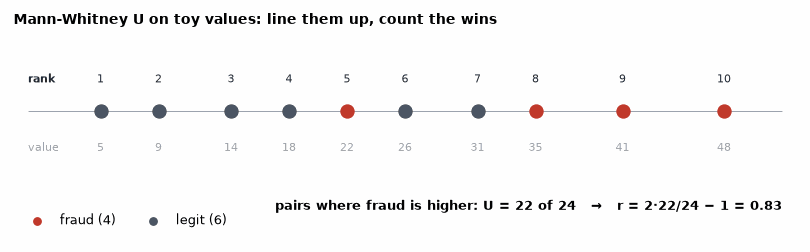

The picture uses 10 toy values.

In [ ]:
rows = []
for col in NUMERIC_TESTED:
    a, b = fraud[col].dropna(), legit[col].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"feature": col, "fraud_median": a.median(), "legit_median": b.median(),
                 "p_value": p, "rank_biserial_r": 2 * u / (len(a) * len(b)) - 1})
mann_whitney = pd.DataFrame(rows).sort_values("rank_biserial_r", key=abs, ascending=False)

In [ ]:
mann_whitney.round(3)

## 7.2 Categorical features → χ² & Cramér's V
**Question:** is each categorical feature linked to fraud?

**Chi-square + Cramér's V in one line** → compare the counts I see in a table with the counts I'd expect if the feature had nothing to do with fraud; Cramér's V turns that gap into a 0-to-1 score.

**How, in 4 steps**
1. Build a table: rows = values of the feature (e.g. category), columns = fraud / legit
2. Expected count of each cell if there is no link → row total × column total / grand total. $H_0$: feature and `is_fraud` are independent (no link)
3. $\chi^2$ → for every cell, (seen − expected)² / expected, then add them up. Big = the table is far from "no link"
4. $\chi^2$ grows with the number of rows and transactions, so scale it down → Cramér's V

$$\chi^2 = \sum_{\text{cells}} \frac{(O - E)^2}{E} \qquad V = \sqrt{\frac{\chi^2}{n\,(\min(r, c) - 1)}}$$
- $O$ → observed (seen) count, $E$ → expected count if there is no link
- $n$ → all transactions, $r$, $c$ → number of rows and columns in the table
- $V$ → **Cramér's V**, from 0 to 1: 0 = no link
- In short → how far the real table is from a "no link" table, scaled to 0 … 1

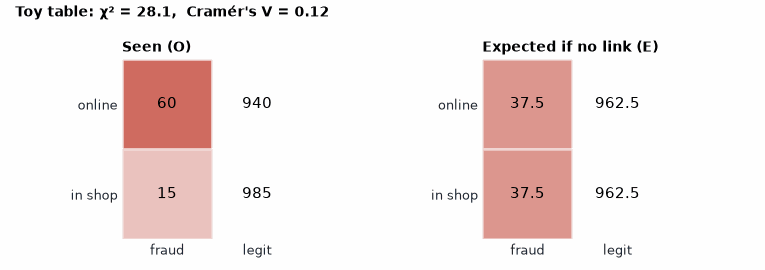

The picture uses a toy 2 × 2 table.

In [ ]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(table)
    n = table.to_numpy().sum()
    return chi2, p, np.sqrt(chi2 / (n * (min(table.shape) - 1)))


rows = []
for col in CATEGORICAL_TESTED:
    chi2, p, v = cramers_v(df[col], df[TARGET])
    rows.append({"feature": col, "n_levels": df[col].nunique(), "chi2": chi2, "p_value": p, "cramers_v": v})
chi_square = pd.DataFrame(rows).sort_values("cramers_v", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
r = mann_whitney.set_index("feature")["rank_biserial_r"].sort_values()
axes[0].barh(r.index, r.values, color=[COLORS[1] if v > 0 else COLORS[0] for v in r.values])
axes[0].axvline(0, c="black", lw=0.8)
axes[0].set(title="Mann-Whitney effect size (rank-biserial r)", xlabel="← lower for fraud | higher for fraud →")
v = chi_square.set_index("feature")["cramers_v"].sort_values()
axes[1].barh(v.index, v.values, color=COLORS[1])
axes[1].set(title="Cramér's V with is_fraud", xlabel="association strength")
savefig(fig, "02_stat_tests")
plt.close(fig)

In [ ]:
chi_square.round(4)

In [ ]:
fig

**Answer:**
- Largest effects: **money spent on the card in the last 24h** (r = 0.73), **amount** (0.67), **night time** (0.62) and **amount vs the card's usual amount** (0.62)
- Fraud comes **sooner after the previous transaction** (r = −0.30) → the burst pattern
- `distance_km` and `log_city_pop` are **not significant** (p > 0.1) → no signal
- `category` (14 levels, V = 0.07) is the useful categorical feature
- `job` and `merchant` → dropped (why below)

**Why I drop `job`** → it has the highest Cramér's V (0.17), but with 494 levels many jobs belong to only one or two holders, so it acts like a **card identifier**: a model would memorise *which customers* were defrauded instead of learning *what fraud looks like*, and fail on new customers. Cramér's V is also inflated by many levels. Same for `merchant`.

# [8/9] Correlation

**Clue** → the four largest effects (24h spend r = 0.73, amount 0.67, night 0.62, amount vs usual 0.62) overlap: one big fraud amount also raises the card's 24h spend and its "amount vs usual".

**I suspect** → some features repeat each other.

**Question** → which ones are redundant, and does it matter for the models?

**Spearman correlation in one line** → replace every value by its rank, then check how well the two rank lists move together.

**How, in 3 steps**
1. Rank each feature on its own: smallest = 1, next = 2, …
2. For every row, take the gap between its two ranks, $d_i$
3. Small gaps everywhere → close to +1 (they go up together); flipped ranks → close to −1

$$\rho = 1 - \frac{6\sum d_i^2}{n(n^2-1)}$$
- $d_i$ → rank gap of row $i$, $n$ → number of rows
- $\rho$ → **Spearman's rho**, from −1 to +1
- In short → "when one goes up, does the other go up too?", using order only, so skew and huge outliers don't fool it

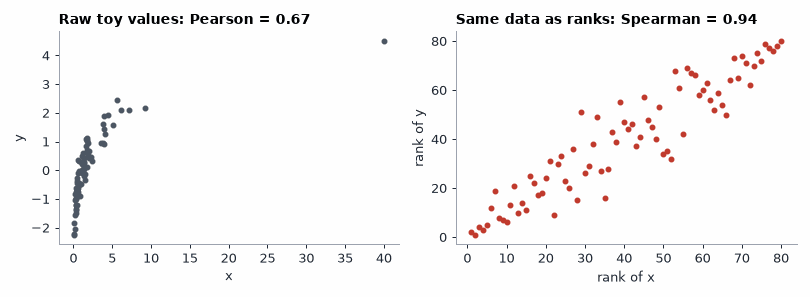

The picture uses toy data with one huge outlier.

In [ ]:
corr = df[NUMERIC_TESTED + [TARGET]].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, mask=mask, cmap="RdGy_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 8}, ax=ax)
ax.set_title("Spearman correlation")
savefig(fig, "02_correlation")
plt.close(fig)

In [ ]:
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3)

In [ ]:
fig

**Answer:**
- The card-history windows correlate with each other (expected) → fine for tree models, a reason to regularise (hold back the weights of) linear models
- No single feature is strongly correlated with `is_fraud` (fraud is rare, so linear correlation is small by construction) → I need models that combine features **non-linearly**

# [9/9] Summary

**Aim** → turn the findings into a feature list for Part 3.

| Signal | Strength | Feature(s) |
|---|---|---|
| High spending on the card in the last 24h | ★★★ | `card_amount_sum_24h` |
| Unusually large amount, esp. \$300–1,100 | ★★★ | `amount`, `log_amount` |
| Amount far above the card's usual spend | ★★★ | `amount_vs_card_mean` |
| Night time (22:00–04:00) | ★★★ | `hour`, `is_night` |
| Burst of activity on the card | ★★ | `secs_since_prev_txn`, `card_txn_count_*` |
| Category (online shopping, grocery) | ★★ | `category` |
| Age | ★ | `age` |
| Distance, city size, gender | ~ | kept, the model decides |
| State, merchant, job | noise / memorisation risk | dropped |

# Part [3/5] Feature Engineering

**Aim** → turn the EDA findings into model-ready features **without leaking the future**. My first version leaked here (features counted over the whole two years, plus a random split). Now every feature uses only what was known *at the moment of the transaction*, I check that by brute force, and I split by time.

**Outlines**
1. What is data leakage?
2. Load full timeline
3. Transaction-level features
4. Card history features
5. Leakage check (brute force)
6. Time-based split
7. Feature overview on the training set
8. Final datasets
9. Summary

In [ ]:
WINDOWS = ("1h", "24h", "7d")
N_CHECK_ROWS = 200
CHECK_SEED = 7
KEEP_COLS = ["trans_id", "trans_time", "card_id", "amount", TARGET] + [f for f in FEATURES if f != "amount"]
SPLIT_COLORS = {"train": "#4b5563", "valid": "#9ca3af", "test": COLORS[1]}

set_style()

# [1/9] What is data leakage?

**Aim** → name the two leaks from my first version, so each one gets its own fix.

**Data leakage in one line** → the model gets information during training or evaluation that it would **not have at prediction time**. Offline scores look great; in real use the model fails.

| Leak | Example | Fix |
|---|---|---|
| **Future information in features** | `transaction_count` per card counted over all 2 years → a January transaction "knew" about December | only look **backwards**: window $[t - W,\ t)$ |
| **Random split on time-ordered data** | train and test shuffled together → the model trains on the days around each test transaction | **time-based split**: train < valid < test |

**Random split vs time split** → a random split shuffles all days, so for almost every test day the model has trained on the day before *and* the day after. Real life only gives you the past. A time split keeps the order.

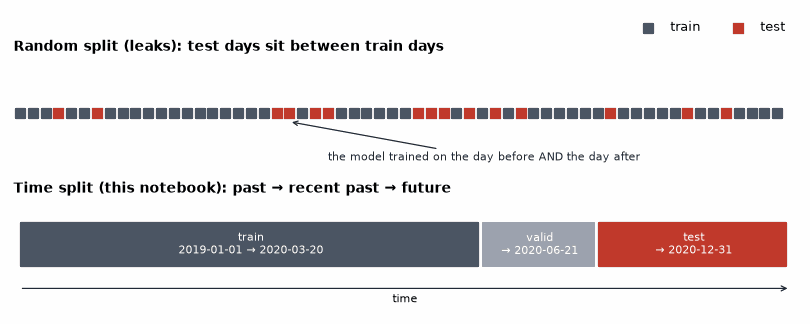

**When is a feature safe?** A feature for transaction $i$ at time $t_i$ on card $c$ is **causal** (uses only the past) if it depends only on

$$\{\text{transaction } j : c_j = c,\ t_j < t_i\}$$
plus transaction $i$'s own fields (amount, time, category …), and never on the label.
- $c_j = c$ → same card
- $t_j < t_i$ → strictly earlier
- In short → a feature may look at this payment and at the card's older payments; nothing later, and never the answer

# [2/9] Load full timeline

**Aim** → stack train and test into one timeline sorted by time.

**Question:** isn't joining train and test a leak itself?

**Answer:** no. At the start of the test period a card's history really does include its earlier (train-period) payments; a real system would know them too. Labels are never used to build features, and the split happens afterwards, by time.

In [ ]:
raw = load_all()

In [ ]:
print(f"{len(raw):,} transactions from {raw.trans_time.min()} to {raw.trans_time.max()}")
raw.groupby("source")[TARGET].agg(["size", "mean"])

# [3/9] Transaction-level features

**Aim** → make features from the payment's own fields (no history needed).

| Feature | Formula / rule | Why (EDA) |
|---|---|---|
| `hour`, `day_of_week` | from `trans_time` | fraud peaks at night |
| `is_night` | $1$ if hour $\in \{22, 23, 0, 1, 2, 3\}$ | 15–30× higher fraud rate |
| `age` | $\frac{t - \text{dob}}{365.25}$ in years **at transaction time** (old version used *today*) | older holders slightly more at risk |
| `log_amount` | $\ln(1 + \text{amount})$ | amount is heavily right-skewed |
| `log_city_pop` | $\ln(1 + \text{city\_pop})$ | skewed |
| `distance_km` | haversine(holder, merchant), see Part 2 [5/9] | test whether distance matters |
| `is_male` | $1$ if gender = M | binary encoding |

In [ ]:
tx = add_transaction_features(raw)
new_tx_cols = ["hour", "day_of_week", "is_night", "age", "log_amount", "log_city_pop", "distance_km", "is_male"]

In [ ]:
tx[new_tx_cols].describe().T.round(2)

# [4/9] Card history features

**Aim** → capture the fraud **burst** pattern (many, large, fast payments on one card) using only the card's past.

**Rolling past-only window in one line** → for each payment, look back a fixed time (1 h, 24 h or 7 days) on the same card and count or add up what happened there, leaving the payment itself out.

**How, in 4 steps**
1. Sort the card's payments by time
2. Stand on payment $i$ at time $t_i$ and draw a window going back $W$ (e.g. 24 h): $[t_i - W,\ t_i)$
3. The window is **left-closed**: the square bracket keeps $t_i - W$, the round bracket leaves out $t_i$ itself (pandas `rolling(W, closed="left")`)
4. Count the payments inside and add up their amounts → move to the next payment and repeat

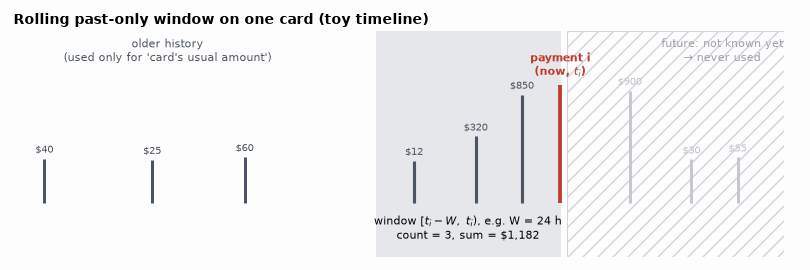

**The formulas** for transaction $i$ on card $c$ at time $t_i$ and window $W$:
The main one is the money spent on the card in the window, because its 24h version had the largest effect in Part 2 (r = 0.73):

$$\text{card\_amount\_sum}_W(i) = \sum_{j:\ c_j = c,\ t_i - W \le t_j < t_i} \text{amount}_j$$

**Part by part**
- $c_j = c$ → only payments of the **same card** → Part 1 found one card per person, so this is one person's own spending, not a crowd average
- $t_i - W \le t_j$ → the window start, kept → $W$ = 1 h, 24 h or 7 days, three speeds of a burst: a fast run of charges shows in the 1 h window, a two-day spree in the 7 d window
- $t_j < t_i$ → **strictly earlier** → the payment itself and everything after it stay out → only what the bank knew just before the swipe; this strict "<" is the leak guard that [5/9] checks by brute force
- $\sum \text{amount}_j$ → adds up the money → a hacked card in Part 2 [6/9] made many \$300–1,100 charges within 1–2 days, so this sum jumps during a burst even when the current payment is small
- Weak spot → on a card's first payments the window is empty (0), and a fraud that is slow or comes first on a quiet card looks normal. Part 5 [8/11] shows exactly such a miss: a \$46.36 fraud on a card that had spent only about \$21 in the previous 24 hours

The other history features follow the same "past only" rule:
- $\text{card\_txn\_count}_W(i) = \#\{j : c_j = c,\ t_i - W \le t_j < t_i\}$ → how many payments in the window
- $\text{secs\_since\_prev\_txn}(i) = t_i - t_{\text{prev}(i)}$ → seconds since the card's previous payment
- $\text{amount\_vs\_card\_mean}(i) = \dfrac{\text{amount}_i}{\text{mean}\{\text{amount}_j : c_j = c,\ t_j < t_i\}}$ → this amount compared with the card's usual amount so far: top = this payment, bottom = the card's earlier payments only (fraud ≈ 5× usual in Part 2)
- $\text{card\_txn\_index}(i)$ → number of earlier payments on the card
- In short → "how busy and how expensive was this card just before now, and how does this payment compare with its usual?" Every number looks only backwards

In [ ]:
feat = add_card_history_features(tx, windows=WINDOWS)
history_cols = [c for c in feat.columns if c.startswith("card_") and c != "card_id"] + \
               ["secs_since_prev_txn", "amount_vs_card_mean"]

In [ ]:
feat[history_cols].describe().T.round(2)

**Note:** `secs_since_prev_txn` and `amount_vs_card_mean` are missing (NaN) only for each card's very first transaction (999 rows), because there is no history yet. Tree models handle NaN on their own; for linear models I fill them in (impute) in Part 4.

In [ ]:
feat[history_cols].isna().sum().loc[lambda s: s > 0]

# [5/9] Leakage check (brute force)

**Aim** → prove that the fast rolling features really use only the past.

**Brute-force check in one line** → recompute the features the slow, obviously correct way, and compare.

**How, in 3 steps**
1. Pick 200 random transactions
2. For each one, loop over that card's earlier payments by hand and compute every history feature again (same window as in the picture in [4/9])
3. Compare with the fast version → any difference = a mismatch

In [ ]:
rng = np.random.default_rng(CHECK_SEED)
sample_idx = rng.choice(len(feat), N_CHECK_ROWS, replace=False)
by_card = {c: g.sort_values("trans_time") for c, g in feat[feat.card_id.isin(feat.card_id.iloc[sample_idx])]
           .groupby("card_id", observed=True)}

mismatches = []
for i in sample_idx:
    row = feat.iloc[i]
    hist = by_card[row.card_id]
    past = hist[hist.trans_time < row.trans_time]
    expected = {"card_txn_index": len(past)}
    for w in WINDOWS:
        in_w = past[past.trans_time >= row.trans_time - pd.Timedelta(w)]
        expected[f"card_txn_count_{w}"] = len(in_w)
        expected[f"card_amount_sum_{w}"] = in_w.amount.sum()
    if len(past):
        expected["amount_vs_card_mean"] = row.amount / past.amount.mean()
    for k, v in expected.items():
        if not np.isclose(row[k], v, rtol=1e-4, atol=1e-2):
            mismatches.append((i, k, row[k], v))

In [ ]:
print(f"checked {N_CHECK_ROWS} random transactions x {len(expected)} features -> {len(mismatches)} mismatches")
mismatches[:5]

**Answer:** 0 mismatches → the fast features match the slow "past only" version: **no future leakage**.

# [6/9] Time-based split

**Aim** → split by time, the way the model would be used in real life: fit on the past, choose on the recent past, test once on the future.

| Set | Period | Used for |
|---|---|---|
| **train** | 2019-01-01 → 2020-03-20 | fitting models |
| **valid** | 2020-03-21 → 2020-06-21 (end of `fraudTrain`) | model selection, tuning, threshold |
| **test** | 2020-06-21 → 2020-12-31 (`fraudTest`) | **one** final, unbiased evaluation |

In [ ]:
feat["split"] = np.where(feat.source == "test", "test",
                         np.where(feat.trans_time < pd.Timestamp(VALID_START), "train", "valid"))
split_summary = feat.groupby("split").agg(start=("trans_time", "min"), end=("trans_time", "max"),
                                          rows=(TARGET, "size"), frauds=(TARGET, "sum"), fraud_rate=(TARGET, "mean"))
split_summary = split_summary.loc[["train", "valid", "test"]]

weekly = feat.set_index("trans_time").groupby([pd.Grouper(freq="W"), "split"])[TARGET].size().unstack()
fig, ax = plt.subplots(figsize=(14, 3.8))
for s, c in SPLIT_COLORS.items():
    ax.fill_between(weekly.index, weekly[s].fillna(0), step="mid", color=c, alpha=0.8, label=s)
ax.set(title="Time-based split (transactions per week)", ylabel="transactions")
ax.legend(loc="upper left")
savefig(fig, "03_time_split")
plt.close(fig)

In [ ]:
split_summary.assign(fraud_rate=lambda d: (d.fraud_rate * 100).round(3).astype(str) + " %")

In [ ]:
fig

# [7/9] Feature overview on the training set

**Question** → the features are now rebuilt past-only on the full timeline. Do they still separate fraud the way the Part 2 tests said? I check on training rows only.

**SMD in one line** → the gap between the fraud mean and the legit mean, measured in standard deviations, so features with different units can be compared.

$$\text{SMD} = \dfrac{\bar{x}_{fraud} - \bar{x}_{legit}}{\sqrt{(s^2_{fraud} + s^2_{legit})/2}}$$
- $\bar{x}_{fraud}$, $\bar{x}_{legit}$ → mean of the feature for fraud and for legit payments
- $s^2_{fraud}$, $s^2_{legit}$ → variance (spread) of each group; the bottom is their average spread
- In short → how many "typical spreads" apart the two groups are: |SMD| > 0.2 small, > 0.5 medium, > 0.8 large

In [ ]:
tr = feat[feat.split == "train"]
f1, f0 = tr[tr[TARGET] == 1], tr[tr[TARGET] == 0]
overview = pd.DataFrame({
    "legit_mean": f0[NUMERIC_FEATURES].mean(),
    "fraud_mean": f1[NUMERIC_FEATURES].mean(),
    "smd": (f1[NUMERIC_FEATURES].mean() - f0[NUMERIC_FEATURES].mean())
           / np.sqrt((f1[NUMERIC_FEATURES].var() + f0[NUMERIC_FEATURES].var()) / 2),
}).sort_values("smd", key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
s = overview["smd"].sort_values()
ax.barh(s.index, s.values, color=[COLORS[1] if v > 0 else COLORS[0] for v in s.values])
ax.axvline(0, c="black", lw=0.8)
ax.set(title="Standardised mean difference (fraud vs legit, train)", xlabel="SMD")
savefig(fig, "03_feature_smd")
plt.close(fig)

In [ ]:
overview.round(3)

In [ ]:
fig

**Answer:** `amount` / `log_amount`, `is_night`, `card_amount_sum_24h` and `amount_vs_card_mean` separate the classes most strongly, in line with the EDA tests. `distance_km` and `log_city_pop` are ≈ 0, as expected.

# [8/9] Final datasets

**Aim** → keep each split as a DataFrame in memory for Parts 4 and 5.

Identifiers (`trans_id`, `card_id`, `trans_time`) are kept for analysis only; they are **not** model inputs.

In [ ]:
splits = {s: feat.loc[feat.split == s, KEEP_COLS].reset_index(drop=True) for s in ["train", "valid", "test"]}
sizes = {s: d.shape for s, d in splits.items()}

In [ ]:
print("model features:", len(FEATURES), "->", FEATURES)
sizes

# [9/9] Summary

**Aim** → list what goes into the model and what I left out on purpose.

- **18 numeric + 1 categorical** features: transaction-level (time, age, amount, distance) and card history (gap since the previous transaction, rolling 1h / 24h / 7d counts and spend, amount vs usual)
- Every history feature is **causal** → verified by brute force on random transactions
- **Time-based split:** train (Jan 2019 – Mar 2020), valid (Mar – Jun 2020), test (Jun – Dec 2020)
- Dropped on purpose: identifiers, names, street, `merchant`, `job`, `state`, `city`, `zip`, `unix_time`

# Part [4/5] Modeling

**Clue** → Part 2 found no single feature strongly correlated with fraud; the strong signals are **combinations**: a big amount, at night, in a burst.

**I suspect** → a model that only adds features up will fall short, and trees that combine them will win.

**Question** → which model catches the most fraud with the fewest false alarms?

**Let's break it down** → baselines → ensembles → does card history help? → imbalance fixes → how much data → Optuna, all compared on the **validation** period. The test set waits for Part 5.

**Outlines**
1. Load datasets
2. Metrics for imbalanced classification
3. Preprocessing
4. Baselines: Dummy, Logistic Regression, Decision Tree
5. Ensemble models: Random Forest, XGBoost, LightGBM
6. Feature ablation: does card history help?
7. Imbalance strategies: none, class weights, undersampling, SMOTE
8. Learning curve: how much data is needed?
9. Hyperparameter tuning with Optuna
10. Benchmark & best model
11. Summary

In [ ]:
import time
import warnings

warnings.filterwarnings("ignore")

import optuna
import lightgbm as lgb
import xgboost as xgb
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = RANDOM_STATE
N_JOBS = -1
N_TRIALS = 40
EARLY_STOPPING = 100
UNDERSAMPLE_RATIO = 0.1
SMOTE_MAJORITY_SAMPLE = 200_000
LEARNING_CURVE_FRACTIONS = [0.02, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
MIN_PRECISION = 0.90
TRANSACTION_ONLY = ["amount", "log_amount", "hour", "day_of_week", "is_night", "age", "is_male",
                    "log_city_pop", "distance_km", "category"]
LGB_BASE = dict(n_estimators=2000, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                colsample_bytree=0.8, random_state=SEED, n_jobs=N_JOBS, verbose=-1)

set_style()
optuna.logging.set_verbosity(optuna.logging.WARNING)

# [1/11] Datasets

**Aim** → take the time-based splits from Part 3 and separate the features $X$ from the answer $y$ (`is_fraud`).

In [ ]:
train, valid = splits["train"].copy(), splits["valid"].copy()
CATS = sorted(train["category"].unique())
for d in (train, valid):
    d["category"] = pd.Categorical(d["category"], categories=CATS)

X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]

In [ ]:
pd.DataFrame({"rows": [len(X_train), len(X_valid)], "frauds": [y_train.sum(), y_valid.sum()],
              "fraud_rate_%": [y_train.mean() * 100, y_valid.mean() * 100]},
             index=["train", "valid"]).round(3)

# [2/11] Metrics for imbalanced classification

**Aim** → pick scores that still mean something when 99.4 % of transactions are legit.

**The four outcomes** → $TP$ = fraud caught, $FP$ = false alarm, $FN$ = fraud missed, $TN$ = legit payment left alone.

**Precision, recall and F1 in one line** → precision = how many alerts are real, recall = how much fraud I catch, F1 = one number that is only high when both are.

$$\text{Precision} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN} \qquad F_1 = 2 \cdot \frac{\text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$$
**Part by part**
- $TP$ → fraud caught → the top of both precision and recall: the only count that pushes both up
- $TP + FP$ (bottom of precision) → every alert raised → grows with each false alarm → precision = the share of the analyst's queue worth opening; in Part 5 each alert costs a \$10 review
- $TP + FN$ (bottom of recall) → all real fraud → fixed by the data (~0.5 % of rows) → recall = the share of it I catch = money saved
- $TN$ → appears **nowhere** → the ~170 legit payments per fraud that are rightly left alone don't count → that is why these scores stay honest under 0.5 % fraud, while accuracy, which counts them, gives a do-nothing model 99.4 %
- $2 \cdot \frac{P \cdot R}{P + R}$ → harmonic mean → dominated by the smaller one: precision 1.0 with recall 0.1 gives $F_1$ = 0.18, not 0.55 → and it holds for **one** threshold only; Part 5 shows the $F_1$-best threshold (0.37) is not the cheapest one (0.02)
- In short → precision = "when I raise an alert, am I right?", recall = "do I raise one for every fraud?". F1 needs both

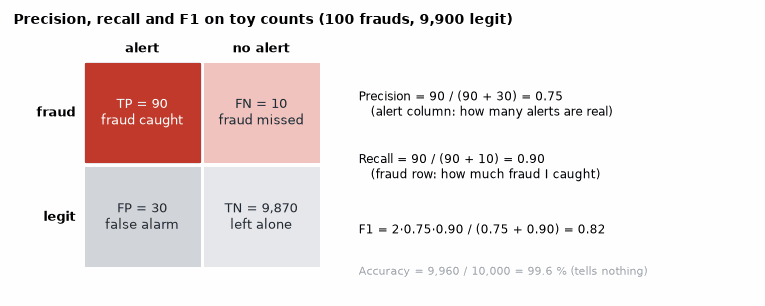

**PR-AUC vs ROC-AUC in one line** → both score the whole ranking over every threshold, but PR-AUC watches the alerts (precision), while ROC-AUC watches the huge pile of legit payments, which makes almost any model look great.

**How, in 5 steps**
1. Sort all transactions by model score, highest first
2. Move the threshold down one transaction at a time; at each step compute recall, precision and the false-alarm rate (FPR = false alarms / all legit payments)
3. **ROC curve** → recall vs FPR. With ~170 legit payments per fraud, even many false alarms barely move FPR, so the curve hugs the top
4. **PR curve** → precision vs recall. Every false alarm lowers precision directly
5. The area under each curve → one number (threshold-free)

$$\text{PR-AUC (average precision)} = \sum_n (R_n - R_{n-1})\, P_n$$
**Part by part**
- $P_n$ → precision at the $n$-th threshold → how clean the alert queue is at that point
- $R_n - R_{n-1}$ → the step in recall → the weight: each threshold counts as much as the extra fraud it catches
- $\sum_n$ → over every threshold, from the top score down → **threshold-free**: it grades the whole ranking, so the alert line can be chosen later, by cost (Part 5)
- No $TN$ again → a random model scores ≈ the fraud rate (0.0056 here), not 0.5 as in ROC-AUC → a PR-AUC is only comparable between periods with similar fraud rates
- In short → precision averaged over every level of recall. A random model scores ≈ the fraud rate, a perfect one 1.0. **Main selection metric**

Two more numbers I report:
- **ROC-AUC** → over-optimistic under heavy imbalance (dominated by the huge number of true negatives)
- **Recall @ 90 % precision** → business view: how much fraud I catch if 9 of 10 alerts must be real

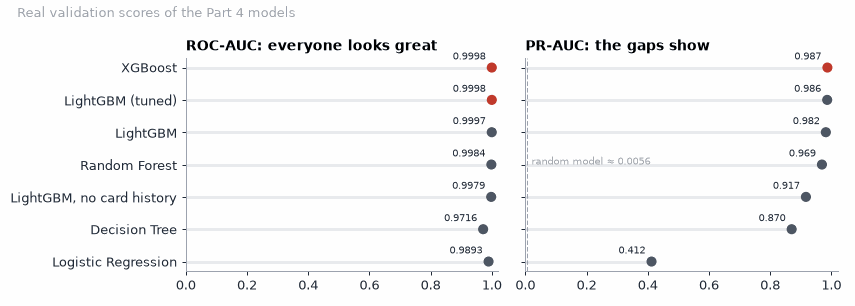

The picture uses the real validation scores of the models in this part (benchmark in [10/11]): ROC-AUC squeezes them all into 0.97–1.00, PR-AUC spreads them from 0.41 to 0.99.

In [ ]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_acc = accuracy_score(y_valid, dummy.predict(X_valid))

In [ ]:
print(f"'Always legit' model -> accuracy {dummy_acc:.2%}, recall 0 %, PR-AUC {y_valid.mean():.4f}")

**Answer:** a model that catches **zero** fraud reaches 99.4 % accuracy → accuracy is useless. I select on **PR-AUC** and report precision / recall / F1 at the F1-best threshold (the cost-best threshold is chosen in Part 5).

# [3/11] Preprocessing

**Aim** → give each model family the inputs it needs.

| Model family | Missing values (first txn of a card) | `category` | Scaling |
|---|---|---|---|
| Linear (Logistic Regression) | median imputation | one-hot | standardise (needed: coefficients are scale-sensitive) |
| sklearn trees (Decision Tree, Random Forest) | median imputation | one-hot | not needed (splits don't care about scale) |
| Gradient boosting (XGBoost, LightGBM) | native NaN handling | native categorical | not needed |

- **Median imputation** → fill a missing value with the middle value of that column
- **One-hot** → one 0/1 column per category value
- **Standardise** → $z = \frac{x - \mu}{\sigma}$, with $\mu$ = column mean and $\sigma$ = column spread. In short → "how many spreads above average is this value?", so every column is on the same scale

In [ ]:
linear_prep = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
])
tree_prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
])

In [ ]:
print("linear input width:", linear_prep.fit_transform(X_train.head(1000)).shape[1], "columns")

Helper used for every experiment: fit on train, predict probabilities on valid, store the scores.

In [ ]:
results, probas, fit_seconds = [], {}, {}


def evaluate(name, model, X_tr=X_train, y_tr=y_train, X_va=X_valid, fit_kwargs=None):
    start = time.time()
    model.fit(X_tr, y_tr, **(fit_kwargs or {}))
    fit_seconds[name] = time.time() - start
    proba = model.predict_proba(X_va)[:, 1]
    thr = best_f1_threshold(y_valid, proba)
    row = score(y_valid, proba, thr, name)
    row["recall@90%prec"] = recall_at_precision(y_valid, proba, MIN_PRECISION)
    row["fit_s"] = fit_seconds[name]
    results.append(row)
    probas[name] = proba
    return model


def results_table(names=None):
    t = pd.DataFrame(results).drop_duplicates("model", keep="last").set_index("model")
    t = t.loc[names] if names else t
    return t.sort_values("pr_auc", ascending=False).round(4)

# [4/11] Baselines

**Aim** → set the bar every serious model must beat with two simple models, and test the suspicion from the start of this part: does a model that only adds features up fall short?

**Logistic Regression in one line** → add up the features with one weight each, then squash the total into a probability.

$$P(y=1 \mid x) = \sigma(w^\top x + b), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}$$
$$\text{fitted by minimising the weighted log loss}\quad -\sum_{i=1}^{n} c_{y_i}\big[\,y_i \ln \hat p_i + (1 - y_i)\ln(1 - \hat p_i)\,\big]$$

**Part by part**
- $x$ → the features of one payment, standardised and one-hot encoded ([3/11]) → each weight multiplies a raw value, so the columns must share one scale
- $w^\top x + b$ → the weighted total, a raw score $z$ (the log-odds) → every feature adds a **fixed** amount, whatever the others say → "big amount **and** night **and** burst" can never count more than the three parts added up, and one weight on amount can only say "bigger = riskier". Part 2 found fraud in **bands** (≈ \$300 and \$800–1,100, largest fraud \$1,376) while normal payments reach \$28,949, so a straight line in amount points the wrong way at the top
- $\sigma(z)$ → **sigmoid** → turns any score into a probability between 0 and 1: $z = 0$ → 0.5, $z = -5$ → 0.007 → it only reshapes the score, it can't add the missing combinations
- $y_i \ln \hat p_i$ → the cost of a **fraud** row, $-\ln \hat p_i$ → a fraud scored 0.75 costs 0.29, one scored 0.001 costs 6.91 (the caught and missed frauds of Part 5 [8/11]) → confident misses explode, so the fit works hardest on the frauds it scores lowest
- $(1 - y_i)\ln(1 - \hat p_i)$ → the same for a **legit** row → punishes a high score on a normal payment (a false alarm)
- $c_{y_i}$ → the **class weight**, `class_weight="balanced"` = $\frac{n}{2\,n_k}$ → one fraud error counts about 170× as much as one legit error. Without it, legit rows carry 99.42 % of the sum and "almost always legit" is the cheapest fit; with it, each class carries half → weak spot: the probabilities come out inflated, they no longer match real fraud rates ([7/11])
- $\sum_{i=1}^{n}$ → every payment adds its cost on its own → assumes the rows are independent, but fraud comes in bursts on a card. The model can only see a burst if the features carry it → that is the job of the card-history features from Part 3
- In short → a weighted vote of the features, turned into a probability, and trained so that confident mistakes cost the most. The border between fraud and legit is a straight line (linear), so a combo like "big amount **and** night" can't be learned

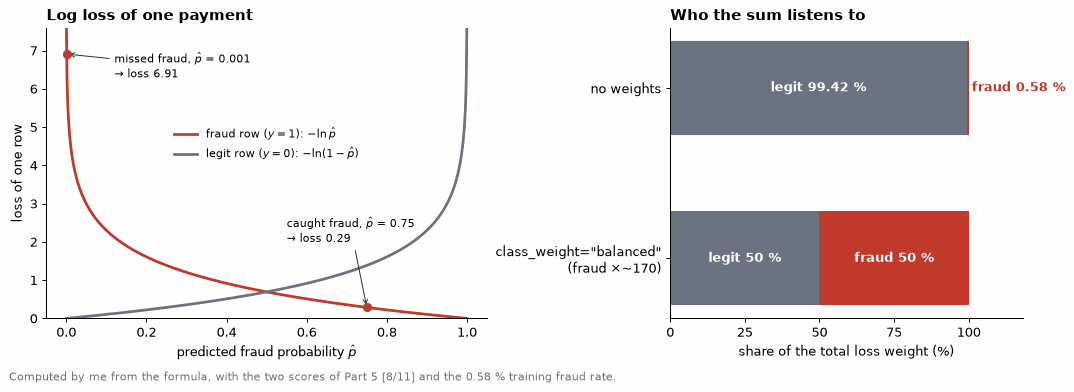

*Computed by me from the formula, with the two scores of Part 5 [8/11] and the 0.58 % training fraud rate.*

**Decision Tree in one line** → ask yes/no questions ("amount > \$300?", "hour ≥ 22?") one after another, each time picking the question that best separates fraud from legit.

$$G = 1 - \sum_k p_k^2 \qquad \text{best split = smallest}\quad \frac{n_L}{n}\,G_L + \frac{n_R}{n}\,G_R$$

**Part by part**
- $p_k$ → share of class $k$ (fraud or legit) in a group → at the root, fraud is 0.58 %
- $\sum_k p_k^2$ → the chance that two random rows from the group share a class → $1 - \dots$ = the chance they differ
- $G$ → **Gini impurity**: 0 = the group is all one class, 0.5 = half and half → at the root $1 - (0.0058^2 + 0.9942^2) \approx 0.0115$: the data already looks almost "pure", so a split that isolates fraud gains very little → with `class_weight="balanced"` each class weighs half, the root starts at 0.5, and fraud splits count
- $\frac{n_L}{n}G_L + \frac{n_R}{n}G_R$ → the two child groups, each weighted by its size → the tree tries every question and keeps the one that lowers this most → greedy, one question at a time, no look-ahead; depth 12 and at least 20 rows per leaf stop it from memorising single payments
- The questions themselves ("amount > \$300?") → two of them in a row carve out a band like \$800–1,100, and "and night" is just one more question down the branch → exactly the combinations the linear model can't add
- In short → how mixed a group is; each split picks the question that leaves the least mixed groups. Non-linear, but one tree changes a lot with small changes in the data (high variance)

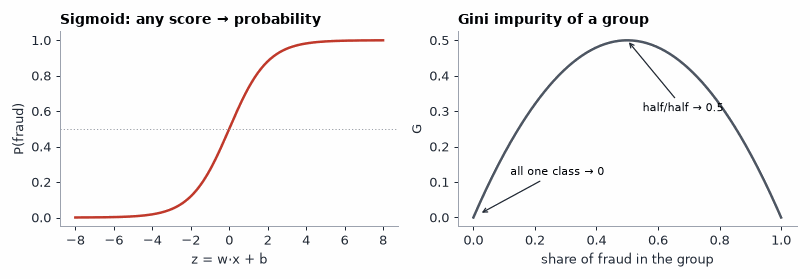

In [ ]:
evaluate("Logistic Regression", make_pipeline(linear_prep, LogisticRegression(
    max_iter=2000, class_weight="balanced", random_state=SEED)))
evaluate("Decision Tree", make_pipeline(tree_prep, DecisionTreeClassifier(
    max_depth=12, min_samples_leaf=20, class_weight="balanced", random_state=SEED)))

In [ ]:
results_table(["Logistic Regression", "Decision Tree"])

**Answer:** both beat random (PR-AUC 0.0056) by a wide margin, and my suspicion held: the tree (0.870) is far ahead of the linear model (0.412), because fraud patterns are non-linear (e.g. *large amount* **and** *night* **and** *burst*).

# [5/11] Ensemble models

**Clue** → one tree (PR-AUC 0.870) left the linear model (0.412) far behind, but a single tree is jumpy: small changes in the data give a different tree.

**Question** → do many trees together get further?

**Let's break it down** → Random Forest averages away one tree's jumpiness (variance); boosting fixes its "too simple" error (bias), one small tree at a time.

**Random Forest (bagging) in one line** → grow many trees, each on a random copy of the data, and average their votes.

**How, in 3 steps**
1. Draw a **bootstrap sample** → pick rows at random with replacement (some twice, some never), as many as in the data
2. Grow a tree on it; at each split, only look at a random subset of features
3. Repeat $B$ times and average → the trees' random mistakes cancel out

$$\hat{p}(x) = \frac{1}{B}\sum_{b=1}^{B} T_b(x)$$
- $T_b(x)$ → fraud probability from tree $b$
- $B$ → number of trees (300 here)
- In short → the average opinion of many slightly different trees, steadier than any one of them

**Gradient boosting (XGBoost, LightGBM) in one line** → add small trees one at a time, each one fixing the mistakes the trees so far still make.

**How, in 4 steps**
1. Start with one simple guess for everyone (e.g. the overall fraud rate)
2. Measure how wrong each payment's current score is: the gradient of the log-loss says which way and how far to move the score
3. Fit a small tree to those errors and add a small step of it to the score
4. Repeat; **early stopping** watches the validation score and stops adding trees when it stops improving

$$F_m(x) = F_{m-1}(x) + \eta\, h_m(x), \qquad h_m \text{ fitted to } \; y_i - \hat p_i \;\text{ (what the log loss still blames)}$$

**Part by part**
- $F_m(x)$ → the score after $m$ trees, in log-odds → the same scale as $z$ in Logistic Regression; $\sigma(F_m)$ turns it into $\hat p$
- $F_{m-1}(x)$ → everything the earlier trees learned → kept frozen; a new tree never undoes an old one, it only adds
- $y_i - \hat p_i$ → what is still wrong for each payment (the slope of the log loss; XGBoost and LightGBM also use its curvature) → a fraud already at 0.99 leaves 0.01, a fraud at 0.001 leaves almost 1 → each new tree spends its splits on the frauds still missed. I suspect this built-in focus on hard cases is one reason rebalancing changes so little in [7/11]
- $h_m(x)$ → a small tree (depth 8 in XGBoost here) → each tree is a set of "if amount … and hour … and 24h spend …" rules, so the sum of many trees can learn the combinations Logistic Regression can't
- $\eta$ → learning rate (0.05 for XGBoost here) → each correction is shrunk, so no single tree can chase noise; smaller = more trees needed, less overfitting
- $m$ → the number of trees, set by **early stopping** on the validation period → the validation set helps choose the model, which is why the boosting scores below are a bit optimistic
- In short → keep adding small corrections until the score is right; smaller steps = slower, but less overfitting

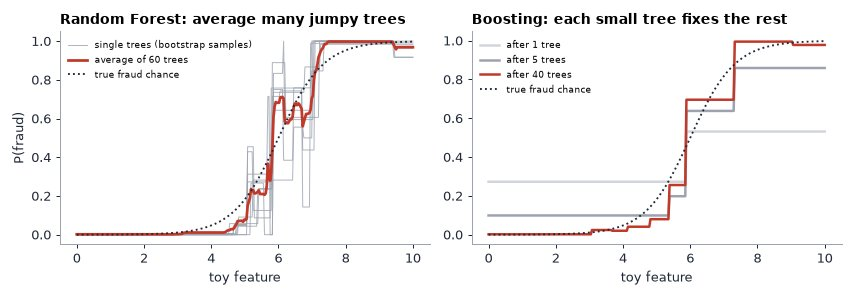

The picture uses one toy feature.

In [ ]:
evaluate("Random Forest", make_pipeline(tree_prep, RandomForestClassifier(
    n_estimators=300, min_samples_leaf=5, max_features="sqrt", class_weight="balanced_subsample",
    n_jobs=N_JOBS, random_state=SEED)))

evaluate("XGBoost", xgb.XGBClassifier(
    n_estimators=2000, learning_rate=0.05, max_depth=8, subsample=0.8, colsample_bytree=0.8,
    tree_method="hist", enable_categorical=True, eval_metric="aucpr", early_stopping_rounds=EARLY_STOPPING,
    random_state=SEED, n_jobs=N_JOBS),
    fit_kwargs=dict(eval_set=[(X_valid, y_valid)], verbose=False))

lgb_default = evaluate("LightGBM", lgb.LGBMClassifier(**LGB_BASE), fit_kwargs=dict(
    eval_set=[(X_valid, y_valid)], eval_metric="average_precision",
    callbacks=[lgb.early_stopping(EARLY_STOPPING, verbose=False)]))

In [ ]:
results_table()

In [ ]:
fig = plot_pr_roc({k: probas[k] for k in results_table().index}, y_valid)
savefig(fig, "04_pr_roc_models")
plt.close(fig)

In [ ]:
fig

**Answer:** the ensembles are far ahead of the baselines.

| Model | Valid PR-AUC | Fit time |
|---|---|---|
| XGBoost | 0.987 | 151 s |
| LightGBM | 0.982 | 35 s |
| Random Forest | 0.969 | 278 s |
| Decision Tree | 0.870 | – |
| Logistic Regression | 0.412 | – |

LightGBM is the fastest ensemble. ROC-AUC runs from 0.972 to 0.9998 and hardly separates the ensembles (Logistic Regression still scores 0.989 with PR-AUC 0.41), which is why PR-AUC is the selection metric.

(!) The boosting models use this validation set for early stopping, so their validation scores are a bit optimistic. The honest number is the test score in Part 5.

# [6/11] Feature ablation: does card history help?

**I'm curious** → the boosting models reach 0.98–0.99. How much of that comes from the card-history features I worked to build leak-free in Part 3?

**Feature ablation in one line** → take features away and see how much the score drops. Here: the same LightGBM, trained with transaction-level features only.

In [ ]:
evaluate("LightGBM - transaction features only", lgb.LGBMClassifier(**LGB_BASE),
         X_tr=X_train[TRANSACTION_ONLY], X_va=X_valid[TRANSACTION_ONLY],
         fit_kwargs=dict(eval_set=[(X_valid[TRANSACTION_ONLY], y_valid)], eval_metric="average_precision",
                         callbacks=[lgb.early_stopping(EARLY_STOPPING, verbose=False)]))

In [ ]:
results_table(["LightGBM", "LightGBM - transaction features only"])

**Answer:** without card history, PR-AUC falls from 0.982 to 0.917 and recall from 0.94 to 0.82 → the **burst behaviour** is a key signal, and building it without leakage was worth the effort.

# [7/11] Imbalance strategies

**Something odd** → LightGBM reached 0.982 on the natural 0.58 % fraud rate without any rebalancing, while the baselines and Random Forest were all given `class_weight`.

**Question** → would rebalancing help it further, and which way?

**The four options, one line each**
- **None** → train on the natural 0.58 % fraud rate
- **Class weights** → keep all rows, but a fraud mistake counts more in the loss (`scale_pos_weight`, part by part below)
- **Random undersampling** → keep all fraud, throw away legit rows at random until it's 1 : 10
- **SMOTE** → make new, synthetic fraud rows between real ones

**SMOTE, how in 4 steps**
1. Take a real fraud row $x_i$
2. Find its $k$ nearest fraud neighbours (the most similar fraud rows, by distance)
3. Pick one of them at random, $x_{nn}$
4. Put a new point somewhere on the line between the two

$$x_{new} = x_i + \lambda\,(x_{nn} - x_i), \qquad \lambda \sim U(0,1)$$
- $x_i$ → a real fraud row, $x_{nn}$ → one of its fraud neighbours
- $\lambda$ → a random number between 0 and 1: 0 = at $x_i$, 1 = at the neighbour, 0.5 = halfway
- In short → a new, made-up fraud that sits between two real frauds

**Class weights, part by part**

$$-\sum_{i} \big[\, w\, y_i \ln \hat p_i + (1 - y_i)\ln(1 - \hat p_i) \,\big], \qquad w = \frac{n_{legit}}{n_{fraud}}$$
- $\frac{n_{legit}}{n_{fraud}}$ → legit rows per fraud row in train → about 170 at 0.58 % fraud
- $w\, y_i \ln \hat p_i$ → every fraud row's log loss is multiplied by $w$ → fraud and legit now carry the same total weight, as in the right panel of the [4/11] log-loss picture
- What it does to $\hat p$ → the model is trained as if fraud were about half of all payments → every probability is pushed up → the **order** of the payments barely changes, so PR-AUC should barely move, but the best threshold should move up
- Weak spot → $\hat p$ stops being a real fraud rate; that matters for calibration (Part 5 [6/11]) and for a dollar-cost threshold
- In short → "a missed fraud hurts 170× more". Undersampling gets a similar effect by throwing legit rows away, SMOTE by adding made-up frauds

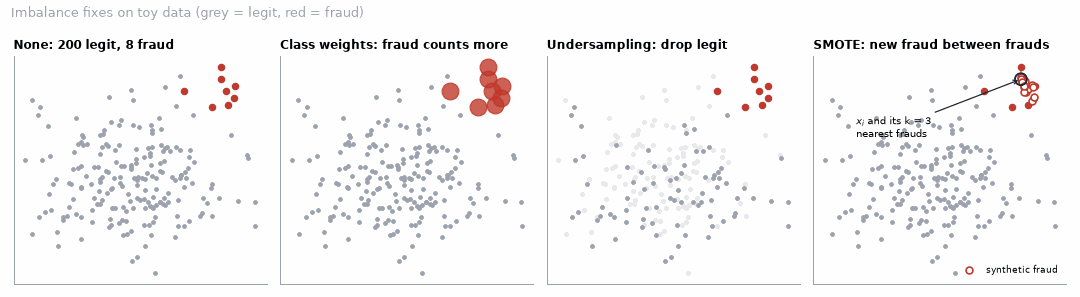

| Strategy | Risk |
|---|---|
| None | the model may under-weight fraud |
| Class weights | probabilities no longer calibrated (they stop matching real fraud rates) |
| Undersampling | throws away information |
| SMOTE | synthetic points can be unrealistic, slow on big data |

All variants use the same LightGBM settings and are scored on the **untouched** validation set (I never resample validation data).

In [ ]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
rng = np.random.default_rng(SEED)
fraud_idx = np.flatnonzero(y_train.values == 1)
legit_idx = np.flatnonzero(y_train.values == 0)

under_idx = np.concatenate([fraud_idx, rng.choice(legit_idx, int(len(fraud_idx) / UNDERSAMPLE_RATIO), replace=False)])
X_under, y_under = X_train.iloc[under_idx], y_train.iloc[under_idx]

smote_idx = np.concatenate([fraud_idx, rng.choice(legit_idx, SMOTE_MAJORITY_SAMPLE, replace=False)])
X_sm_in = pd.get_dummies(X_train.iloc[smote_idx], columns=CATEGORICAL_FEATURES, dtype=float)
sm_medians = X_sm_in.median()
X_smote, y_smote = SMOTE(sampling_strategy=UNDERSAMPLE_RATIO, random_state=SEED).fit_resample(
    X_sm_in.fillna(sm_medians), y_train.iloc[smote_idx])
X_valid_dummies = pd.get_dummies(X_valid, columns=CATEGORICAL_FEATURES, dtype=float)[X_sm_in.columns].fillna(sm_medians)

In [ ]:
pd.DataFrame({"rows": [len(X_train), len(X_under), len(X_smote)],
              "fraud_share_%": [y_train.mean() * 100, y_under.mean() * 100, y_smote.mean() * 100]},
             index=["original", "undersampled", "SMOTE"]).round(2)

In [ ]:
es = lambda Xv: dict(eval_set=[(Xv, y_valid)], eval_metric="average_precision",
                     callbacks=[lgb.early_stopping(EARLY_STOPPING, verbose=False)])
results.append({**results_table().loc["LightGBM"].to_dict(), "model": "Imbalance: none"})
probas["Imbalance: none"] = probas["LightGBM"]
evaluate("Imbalance: class weights", lgb.LGBMClassifier(**LGB_BASE, scale_pos_weight=pos_weight), fit_kwargs=es(X_valid))
evaluate("Imbalance: undersampling 1:10", lgb.LGBMClassifier(**LGB_BASE), X_tr=X_under, y_tr=y_under,
         fit_kwargs=es(X_valid))
evaluate("Imbalance: SMOTE 1:10", lgb.LGBMClassifier(**LGB_BASE), X_tr=X_smote, y_tr=y_smote,
         X_va=X_valid_dummies, fit_kwargs=es(X_valid_dummies))
imbalance_names = ["Imbalance: none", "Imbalance: class weights", "Imbalance: undersampling 1:10", "Imbalance: SMOTE 1:10"]

In [ ]:
results_table(imbalance_names)

In [ ]:
fig = plot_pr_roc({k: probas[k] for k in imbalance_names}, y_valid)
savefig(fig, "04_pr_roc_imbalance")
plt.close(fig)

In [ ]:
fig

**Answer:** the choice barely matters here: all four land between 0.980 and 0.984.

| Strategy | Valid PR-AUC | Best-F1 threshold |
|---|---|---|
| none | 0.9819 | 0.30 |
| class weights | 0.9816 | 0.81 |
| undersampling 1 : 10 | 0.9803 | 0.95 |
| SMOTE 1 : 10 | 0.9839 | 0.81 |

- SMOTE is nominally highest, but a gap of 0.002 from a single time split is too small to justify synthetic data and the extra preprocessing
- Undersampling is the fastest (10 s vs 35 s) at a small cost
- Rebalancing mostly **moves the threshold** (0.30 → 0.81–0.95), as the class-weight breakdown predicted: the scores are pushed up, the order stays

**Decision:** keep the natural distribution. It uses all real data and keeps probabilities meaningful; the threshold is set directly in Part 5.

# [8/11] Learning curve: how much data is needed?

**Clue** → undersampling threw away most legit rows and lost only 0.0016 PR-AUC (0.9803 vs 0.9819).

**I'm curious** → if dropping rows costs so little, does the model need all the training data, or would less do? (My first version asked this with undersampling.)

**Learning curve in one line** → train the same model on more and more data and watch the validation score.

**How** → train LightGBM on the most recent fraction $f$ of the training period (recent data is closest to the future), score on validation, repeat for a bigger $f$.

In [ ]:
curve = []
for f in LEARNING_CURVE_FRACTIONS:
    n = int(len(X_train) * f)
    Xs, ys = X_train.iloc[-n:], y_train.iloc[-n:]
    m = lgb.LGBMClassifier(**LGB_BASE).fit(Xs, ys, **es(X_valid))
    curve.append({"fraction": f, "rows": n, "frauds": int(ys.sum()),
                  "pr_auc": average_precision_score(y_valid, m.predict_proba(X_valid)[:, 1])})
curve = pd.DataFrame(curve)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(curve["rows"], curve["pr_auc"], marker="o", color=COLORS[1])
for _, r in curve.iterrows():
    ax.annotate(f"{int(r.frauds):,} frauds", (r.rows, r.pr_auc), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=8)
ax.set(xscale="log", xlabel="training rows (most recent, log scale)", ylabel="valid PR-AUC", title="Learning curve")
savefig(fig, "04_learning_curve")
plt.close(fig)

In [ ]:
curve.round(4)

In [ ]:
fig

**Answer:** more data still helps a little, so I use all of it. PR-AUC rises steeply up to 20 % of the data (0.813 → 0.951), then slowly: 0.968 at 40 %, 0.973 at 70 %, 0.982 at 100 %.

Each extra fraction also adds *older* data, so this curve mixes data size with data age.

# [9/11] Hyperparameter tuning with Optuna

**Clue** → more data still helps, but only slowly (0.973 at 70 % → 0.982 at 100 %), and the imbalance fix doesn't matter. The next gain has to come from the model's own settings.

**Aim** → search LightGBM's hyperparameters (knobs set before training, like tree size and learning rate) for the best validation PR-AUC.

**Optuna TPE in one line** → after each try, look at which settings did well and which did badly, and try next where good settings are much more common than bad ones.

**How, in 4 steps** (Tree-structured Parzen Estimator, TPE)
1. Try a few random settings and score each on validation
2. Split the tries into "good" (the best few) and "bad" (the rest)
3. Draw a smooth density over each group: where do good settings sit, where do bad ones sit
4. Next try = the setting where good is most common compared with bad → score it → back to step 2 (40 trials here)

$$\theta_{next} = \arg\max_\theta \frac{p(\theta \mid \text{good})}{p(\theta \mid \text{bad})}$$
- $\theta$ → one set of settings
- $p(\theta \mid \text{good})$, $p(\theta \mid \text{bad})$ → the two densities from step 3
- In short → go where good results gathered and bad ones didn't. Grid search (my first version) tries every combination blindly, so TPE finds better settings for the same budget. The number of trees is set by early stopping inside each trial

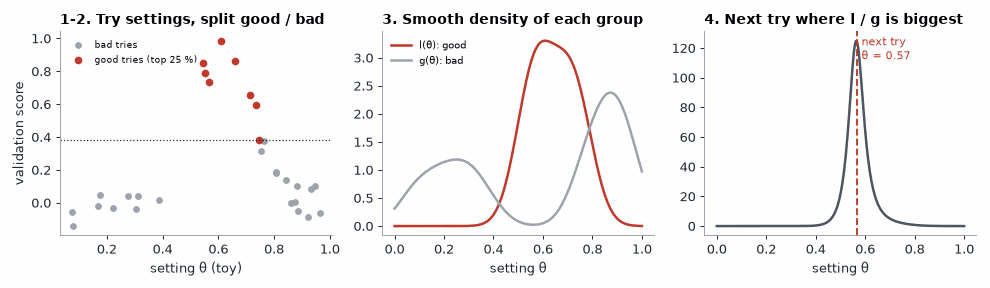

The picture uses one toy setting and a toy score.

In [ ]:
def objective(trial):
    params = dict(
        LGB_BASE,
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        num_leaves=trial.suggest_int("num_leaves", 15, 255, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 10, 300, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    )
    m = lgb.LGBMClassifier(**params).fit(X_train, y_train, **es(X_valid))
    trial.set_user_attr("n_estimators", m.best_iteration_)
    return average_precision_score(y_valid, m.predict_proba(X_valid)[:, 1])


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.enqueue_trial({k: LGB_BASE[k] for k in ["learning_rate", "num_leaves", "subsample", "colsample_bytree"]}
                    | {"min_child_samples": 20, "reg_alpha": 1e-3, "reg_lambda": 1e-3})
study.optimize(objective, n_trials=N_TRIALS)
best_params = dict(LGB_BASE, **study.best_params)
best_params["n_estimators"] = study.best_trial.user_attrs["n_estimators"]

trials = study.trials_dataframe(attrs=("number", "value", "params"))
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(trials["number"], trials["value"], "o", color=COLORS[0], alpha=0.6, label="trial")
axes[0].plot(trials["number"], trials["value"].cummax(), color=COLORS[1], label="best so far")
axes[0].set(xlabel="trial", ylabel="valid PR-AUC", title="Optuna optimisation history")
axes[0].legend()
importance = pd.Series(optuna.importance.get_param_importances(study)).sort_values()
axes[1].barh(importance.index, importance.values, color=COLORS[1])
axes[1].set(title="Hyperparameter importance (fANOVA)")
savefig(fig, "04_optuna")
plt.close(fig)

In [ ]:
print(f"best valid PR-AUC: {study.best_value:.4f} (default LightGBM: {results_table().loc['LightGBM', 'pr_auc']:.4f})")
best_params

In [ ]:
fig

# [10/11] Benchmark & best model

**Aim** → compare every experiment on validation and keep the best model for Part 5.

**Decision:** untuned XGBoost (0.9870) and tuned LightGBM (0.9863) are basically tied (gap 0.0007). I keep LightGBM because it trains about 4× faster, which matters for retraining and for SHAP.

In [ ]:
tuned = evaluate("LightGBM (tuned)", lgb.LGBMClassifier(**best_params))
benchmark = results_table()

fig, ax = plt.subplots(figsize=(10, 6))
b = benchmark["pr_auc"].sort_values()
ax.barh(b.index, b.values, color=[COLORS[1] if "tuned" in i else COLORS[0] for i in b.index])
for i, v in enumerate(b.values):
    ax.text(v, i, f" {v:.3f}", va="center", fontsize=9)
ax.set(title="Validation PR-AUC of every experiment", xlabel="PR-AUC", xlim=(0, 1.08))
savefig(fig, "04_benchmark")
plt.close(fig)

BEST = {"features": FEATURES, "categories": CATS, "params": best_params,
        "valid_pr_auc": float(benchmark.loc["LightGBM (tuned)", "pr_auc"])}

In [ ]:
benchmark

In [ ]:
fig

# [11/11] Summary

**Aim** → the short version of Part 4, and what goes on to Part 5.

- **Metric:** PR-AUC (threshold-free, honest under 0.5 % fraud); accuracy is meaningless here
- **Models:** gradient boosting (0.98–0.99) > Random Forest (0.969) > Decision Tree (0.870) > Logistic Regression (0.412)
- **Feature engineering:** card-history features lift PR-AUC from 0.917 to 0.982
- **Imbalance:** the four strategies differ by at most 0.004, so I keep the natural distribution and adjust the threshold
- **Tuning:** Optuna (TPE, 40 trials) improved LightGBM from 0.9819 to 0.9863; the tuned LightGBM and its parameters go straight to Part 5
- **Next:** Part 5 refits on train + valid and evaluates **once** on the test period

# Part [5/5] Evaluation & Explainability

**Clue** → the tuned LightGBM scores 0.986 on validation, but that same period chose its settings and its number of trees, so the number is a bit optimistic (the (!) in Part 4 [5/11]).

**Question** → how good is it on six future months it has never seen, and can I explain why it flags a payment?

**Let's break it down** → pick the threshold on validation → refit → test **once** → then dollars, calibration, SHAP, errors and stability over time.

**Outlines**
1. Model & data
2. Choose the decision threshold (validation)
3. Final model: refit on train + valid
4. Test performance
5. Business impact in dollars
6. Calibration
7. Global explainability: feature importance & SHAP
8. Local explainability: why was this transaction flagged?
9. Error analysis
10. Stability over time
11. Summary

In [ ]:
warnings.filterwarnings("ignore")

import shap
from sklearn.metrics import brier_score_loss

REVIEW_COST = 10.0
MIN_PRECISION = 0.90
SHAP_SAMPLE = 20_000
AMOUNT_BINS = [0, 50, 200, 500, 800, 1000, 1500, 30000]
CALIBRATION_BINS = [0, 0.001, 0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99, 1.0]

set_style()

# [1/11] Model & data

**Aim** → load the tuned LightGBM from Part 4 (trained on train only) and all three splits from Part 3.

In [ ]:
splits = {s: d.copy() for s, d in splits.items()}
for d in splits.values():
    d["category"] = pd.Categorical(d["category"], categories=BEST["categories"])
train, valid, test = splits["train"], splits["valid"], splits["test"]
model_train_only = tuned

In [ ]:
print({s: d.shape for s, d in splits.items()})
BEST["params"]

# [2/11] Choose the decision threshold (validation)

**Aim** → choose the fraud probability above which I raise an alert, on **validation** only (never on test).

**Threshold in one line** → the model gives a probability $\hat{p} = P(\text{fraud} \mid x)$; I alert when $\hat{p} \ge \tau$. A lower $\tau$ = more alerts: more fraud caught, more reviews to pay for.

**Two ways to pick $\tau$**
1. **F1-best** → try every $\tau$ and keep the one with the highest $F_1$. Treats precision and recall as equally important
2. **Cost-best (business)** → try every $\tau$, add up the dollars each one costs, keep the cheapest

$$\text{Cost}(\tau) = 10 \cdot \#\{\hat{p} \ge \tau\} + \sum_{i:\ y_i = 1,\ \hat{p}_i < \tau} \text{amount}_i$$

**Part by part**
- $\tau$ → the alert line → the only thing I choose here; the model and its ranking stay fixed
- $10 \cdot \#\{\hat{p} \ge \tau\}$ → review fees: every alert costs \$10, real or not → grows step by step as $\tau$ goes down
- $\sum \text{amount}_i$ over the frauds with $\hat p_i < \tau$ → money lost: every missed fraud costs **its own amount** → most fraud sits at ≈ \$300 or \$800–1,100 (Part 2), so one missed fraud costs as much as 30 to 110 reviews → the cheapest $\tau$ should sit far below the $F_1$-best one, which weighs a miss and a false alarm about the same
- What it leaves out → a caught fraud counts as fully saved, a false alarm costs only the review (no annoyed customer, no blocked card), and \$10 is my assumption → change these and $\tau$ moves
- Why validation → $\tau$ is a choice like any other; picking it on the test months would tune the test score
- In short → the bill = review fees + money lost to the frauds I didn't flag. A low $\tau$ raises the fees, a high $\tau$ raises the losses; the best $\tau$ sits at the bottom of that bill

The next cells draw the real cost curve on validation.

In [ ]:
p_valid = model_train_only.predict_proba(valid[FEATURES])[:, 1]
tau_cost, cost_curve = best_cost_threshold(valid[TARGET], p_valid, valid["amount"], REVIEW_COST)
tau_f1 = best_f1_threshold(valid[TARGET], p_valid)
no_model_cost = valid.loc[valid[TARGET] == 1, "amount"].sum()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(cost_curve["threshold"], cost_curve["cost"] / 1e3, color=COLORS[0])
ax.axvline(tau_cost, color=COLORS[1], ls="--", label=f"cost-optimal τ = {tau_cost:.2f}")
ax.axvline(tau_f1, color="black", ls=":", label=f"F1-optimal τ = {tau_f1:.2f}")
ax.set(xlabel="threshold τ", ylabel="cost (thousand $)", title="Validation cost vs threshold")
ax.legend()
savefig(fig, "05_cost_threshold")
plt.close(fig)

In [ ]:
pd.DataFrame([
    {"threshold": "no model (miss everything)", "cost_$": no_model_cost},
    {"threshold": f"F1-optimal τ={tau_f1:.2f}", "cost_$": fraud_cost(valid[TARGET], p_valid, valid["amount"], tau_f1, REVIEW_COST)},
    {"threshold": f"cost-optimal τ={tau_cost:.2f}", "cost_$": cost_curve["cost"].min()},
]).round(0)

In [ ]:
fig

**Answer:** as the formula suggested, the cost-best threshold ($\tau$ = 0.02) is far **lower** than the F1-best one (0.37): a missed fraud costs hundreds of dollars, a review only \$10, so it pays to alert more often.

| On validation | Cost |
|---|---|
| no model (miss everything) | \$671,623 |
| F1-best $\tau$ = 0.37 | \$30,047 |
| cost-best $\tau$ = 0.02 | \$18,168 |

I use $\tau_{cost}$ for the final evaluation.

# [3/11] Final model: refit on train + valid

**Aim** → refit on all data before the test period (Jan 2019 – Jun 2020) with the tuned settings, so the model has seen the most recent patterns. Number of trees = the early-stopping value found in Part 4.

In [ ]:
train_valid = pd.concat([train, valid], ignore_index=True)
final_model = lgb.LGBMClassifier(**BEST["params"]).fit(train_valid[FEATURES], train_valid[TARGET])
p_test = final_model.predict_proba(test[FEATURES])[:, 1]
test["proba"] = p_test
test["alert"] = (p_test >= tau_cost).astype(int)

In [ ]:
print(f"trained on {len(train_valid):,} rows; test alerts: {test.alert.sum():,} of {len(test):,} transactions")

# [4/11] Test performance

**Question** → does the validation score hold on six months of **future** data the model has never seen?

**What to look for** → PR-AUC close to the validation score (0.986) means the time split held up; recall and precision at $\tau_{cost}$ = how much fraud is caught and how many alerts are real.

In [ ]:
y_test = test[TARGET]
test_metrics = pd.DataFrame([
    score(y_test, p_test, tau_cost, f"cost-optimal τ={tau_cost:.2f}"),
    score(y_test, p_test, tau_f1, f"F1-optimal τ={tau_f1:.2f}"),
]).set_index("model")
test_metrics["recall@90%prec"] = recall_at_precision(y_test, p_test, MIN_PRECISION)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
plot_pr_roc({"LightGBM (final)": p_test}, y_test, ax=axes[:2])
plot_confusion(y_test, p_test, tau_cost, ax=axes[2], title=f"Test confusion matrix @ τ={tau_cost:.2f}")
fig.tight_layout()
savefig(fig, "05_test_performance")
plt.close(fig)

In [ ]:
test_metrics.round(4)

In [ ]:
fig

# [5/11] Business impact in dollars

**Aim** → put the test result in dollars.

- **Fraud caught** $= \sum_{TP} \text{amount}$ → money in the frauds I flagged
- **Fraud missed** $= \sum_{FN} \text{amount}$ → money in the frauds I let through
- **Review cost** $= 10 \cdot \#\text{alerts}$
- **Net saving** $=$ fraud caught $-$ review cost
- In short → what the alerts saved, minus what checking them cost

In [ ]:
fraud_amount = test.loc[y_test == 1, "amount"]
caught = test.loc[(y_test == 1) & (test.alert == 1), "amount"].sum()
missed = test.loc[(y_test == 1) & (test.alert == 0), "amount"].sum()
review = test.alert.sum() * REVIEW_COST
impact = pd.Series({
    "total fraud $": fraud_amount.sum(),
    "fraud caught $": caught,
    "fraud missed $": missed,
    "share of fraud $ caught": caught / fraud_amount.sum(),
    "alerts": test.alert.sum(),
    "alerts per day": test.alert.sum() / test.trans_time.dt.date.nunique(),
    "review cost $": review,
    "net saving $": caught - review,
})

In [ ]:
impact.apply(lambda v: f"{v:,.2%}" if v < 1 else f"{v:,.0f}")

# [6/11] Calibration

**I'm curious** → the cost-best alert line is a probability of only 0.02. Can the scores be read literally: when the model says "30 % fraud", is it fraud about 30 % of the time?

**I suspect** → mostly yes, because I kept the natural class balance in Part 4 [7/11], and class weights are what usually inflate the probabilities.

**Calibration in one line** → group payments by predicted probability, and compare each group's average prediction with how often it really was fraud.

**How, in 3 steps** (reliability curve)
1. Cut the predictions into bins (0–0.001, 0.001–0.01, …, 0.99–1)
2. In each bin → mean predicted probability and real fraud rate
3. Plot one against the other: on the diagonal = perfect, above it = under-confident (real rate higher than predicted), below = over-confident

**Brier score in one line** → the average squared gap between the predicted probability and what really happened (1 or 0).

$$\text{BS} = \frac{1}{n}\sum_i (\hat{p}_i - y_i)^2$$
- $\hat{p}_i$ → predicted probability of fraud, $y_i$ → 1 if fraud, 0 if not
- $n$ → number of payments
- In short → a penalty per payment, averaged: saying 0.9 for a real fraud costs 0.01, saying 0.1 for it costs 0.81. Lower is better, 0 = perfect

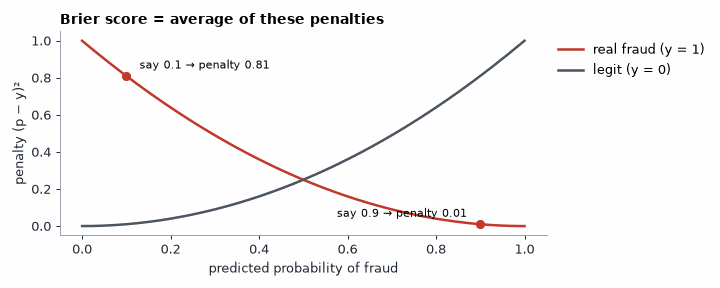

In [ ]:
calibration = (pd.DataFrame({"predicted": p_test, "fraud": y_test.values})
               .groupby(pd.cut(p_test, CALIBRATION_BINS), observed=True)
               .agg(transactions=("fraud", "size"), mean_predicted=("predicted", "mean"), observed_rate=("fraud", "mean")))
brier = brier_score_loss(y_test, p_test)
brier_base = brier_score_loss(y_test, np.full(len(y_test), y_test.mean()))

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot([1e-4, 1], [1e-4, 1], ls="--", c="grey", label="perfect")
plotted = calibration[calibration["observed_rate"] > 0]
ax.plot(plotted["mean_predicted"], plotted["observed_rate"], marker="o", color=COLORS[1], label="LightGBM")
ax.set(xscale="log", yscale="log", xlabel="mean predicted probability", ylabel="observed fraud rate",
       title="Reliability curve (test)")
ax.legend()
savefig(fig, "05_calibration")
plt.close(fig)

In [ ]:
print(f"Brier score: {brier:.5f}  (always predicting the base rate: {brier_base:.5f})")
calibration.round(4)

In [ ]:
fig

**Answer:** only partly, so I was half right.
- **Extremes are reliable** → above 0.9 predicted, 99 % or more are fraud; below 0.001, almost none are
- **The middle is under-confident** → predicted 0.17 corresponds to an observed rate of 0.39, and 0.02 to 0.07

Why that's OK here → the ranking is excellent, and the threshold was chosen by cost, not by reading probabilities literally. To show the score as a real likelihood, I'd first recalibrate it (e.g. isotonic regression: a step-shaped mapping from score to real rate, fitted on a held-out period).

# [7/11] Global explainability: feature importance & SHAP

**Question** → the ranking works on the test months; an analyst also needs to know *why*. Which features drive the model overall, and do they match the Part 2 leads (24h spend, amount, night)?

**SHAP in one line** → split each prediction into a starting value plus one push per feature (up or down), so that the pushes add up exactly to the model's score.

**How, in 4 steps** (SHapley Additive exPlanations)
1. Start from the average score over all payments, in log-odds (the model's raw score before it becomes a probability) → $\phi_0$
2. Add the features one by one, in some order, and note how much each one moves the score
3. The order changes the moves, so average each feature's move over all possible orders → its **Shapley value** $\phi_j$ (an idea from game theory for sharing a prize fairly between players)
4. **Global view** → do this for 20,000 test payments; a feature with big pushes on many payments matters most

$$f(x) = \phi_0 + \sum_{j=1}^{M} \phi_j$$
- $f(x)$ → the model's score for payment $x$ (log-odds)
- $\phi_0$ → the average score (step 1), $\phi_j$ → push of feature $j$ (step 3), $M$ → number of features
- In short → score = average + the push of every feature. Unlike counting splits, SHAP is consistent and shows **direction**: in the summary plot, red = high feature value, dots to the right = pushed towards fraud

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
fraud_rows = np.flatnonzero(y_test.values == 1)
legit_rows = rng.choice(np.flatnonzero(y_test.values == 0), SHAP_SAMPLE - len(fraud_rows), replace=False)
shap_rows = np.concatenate([fraud_rows, legit_rows])
X_shap = test.iloc[shap_rows][FEATURES]

explainer = shap.TreeExplainer(final_model)
shap_values = explainer(X_shap)
gain = pd.Series(final_model.booster_.feature_importance("gain"), index=FEATURES).sort_values()
mean_abs_shap = pd.Series(np.abs(shap_values.values).mean(0), index=FEATURES).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].barh(gain.index, gain.values / gain.sum(), color=COLORS[0])
axes[0].set(title="LightGBM importance (share of total gain)")
plt.sca(axes[1])
shap.plots.beeswarm(shap_values, max_display=19, show=False, plot_size=None)
axes[1].set_title("SHAP values (test sample, all frauds included)")
fig.tight_layout()
savefig(fig, "05_shap_summary")
plt.close(fig)

In [ ]:
mean_abs_shap.round(3)

In [ ]:
fig

## 7.1 Dependence: how do the top features act?
**Something odd** → next to `amount`, `category`, `card_amount_sum_24h` and `is_night`, the top list holds `card_txn_index`, which is missing from the Part 2 feature table.

**I'm curious** → what shape does each top feature's effect have? I plot its SHAP value (push) against the feature's own value.

**What to look for** → dots going up = higher values push towards fraud; a flat part = the feature doesn't matter in that range.

In [ ]:
top4 = mean_abs_shap.index[:4].tolist()
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, f in zip(axes, top4):
    shap.plots.scatter(shap_values[:, f], ax=ax, show=False, color=COLORS[0], alpha=0.3, dot_size=6)
    ax.axhline(0, c="black", lw=0.8)
    ax.set_title(f)
fig.tight_layout()
savefig(fig, "05_shap_dependence")
plt.close(fig)

In [ ]:
top4

In [ ]:
fig

# [8/11] Local explainability: why was this transaction flagged?

**Question** → the global view says what matters on average. Why was *one* payment flagged, or missed, the way an analyst would see it next to an alert?

**Let's break it down** → one caught fraud and one missed fraud from the test months, each as a waterfall

**How to read a waterfall** → it starts at the average log-odds $\phi_0$ at the bottom; each bar is one feature's push $\phi_j$ (red → towards fraud, blue → towards legit); the top is this transaction's score.

In [ ]:
shap_df = test.iloc[shap_rows].reset_index(drop=True)
caught_i = shap_df.index[(shap_df[TARGET] == 1) & (shap_df.alert == 1)][0]
missed_candidates = shap_df.index[(shap_df[TARGET] == 1) & (shap_df.alert == 0)]
missed_i = missed_candidates[0] if len(missed_candidates) else None

fig = plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values[caught_i], max_display=10, show=False)
plt.title("Caught fraud", loc="left")
savefig(plt.gcf(), "05_shap_waterfall_caught")
fig_caught = plt.gcf()
plt.close(fig_caught)

In [ ]:
shap_df.loc[caught_i, ["trans_time", "category", "amount", "hour", "card_amount_sum_24h", "amount_vs_card_mean", "proba"]]

In [ ]:
fig_caught

In [ ]:
if missed_i is not None:
    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(shap_values[missed_i], max_display=10, show=False)
    plt.title("Missed fraud", loc="left")
    savefig(plt.gcf(), "05_shap_waterfall_missed")
    fig_missed = plt.gcf()
    plt.close(fig_missed)

In [ ]:
shap_df.loc[missed_i, ["trans_time", "category", "amount", "hour", "card_amount_sum_24h", "amount_vs_card_mean", "proba"]]

In [ ]:
fig_missed

**Answer:**
- **Caught fraud** → only \$24.84, yet flagged (score 0.75), mostly because the card spent \$1,935 in the previous 24 hours, plus category and night time. **The amount alone would never have caught it; card history did**
- **Missed fraud** → \$46.36 at 22:00, score 0.001: the amount is small and the card spent only about \$21 in the previous 24 hours, so there is little to tell it apart from normal spending

# [9/11] Error analysis

**Clue** → the missed fraud in [8/11] was a small \$46.36 payment on a quiet card.

**I suspect** → most misses are like it: small, cheap frauds that look like normal shopping.

**Let's break it down** → 1) recall per amount band and per category 2) median amount, hour, 24h spend and amount vs usual for caught, missed, false alarms and correct legit

In [ ]:
test["outcome"] = np.select(
    [(y_test == 1) & (test.alert == 1), (y_test == 1) & (test.alert == 0), (y_test == 0) & (test.alert == 1)],
    ["TP (caught)", "FN (missed)", "FP (false alarm)"], "TN")
test["amount_band"] = pd.cut(test["amount"], AMOUNT_BINS)
fraud_test = test[y_test == 1]
recall_by_band = fraud_test.groupby("amount_band", observed=True)["alert"].agg(["size", "mean"]).rename(
    columns={"size": "frauds", "mean": "recall"})
recall_by_cat = fraud_test.groupby("category", observed=True)["alert"].agg(["size", "mean"]).rename(
    columns={"size": "frauds", "mean": "recall"}).sort_values("recall")

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
axes[0].bar(recall_by_band.index.astype(str), recall_by_band["recall"], color=COLORS[1])
axes[0].set(title="Recall by amount band (test)", ylabel="share of fraud caught", ylim=(0, 1.05))
axes[0].tick_params(axis="x", rotation=30)
axes[1].barh(recall_by_cat.index.astype(str), recall_by_cat["recall"], color=COLORS[1])
axes[1].set(title="Recall by category (test)", xlabel="share of fraud caught", xlim=(0, 1.05))
fig.tight_layout()
savefig(fig, "05_error_analysis")
plt.close(fig)

In [ ]:
recall_by_band.round(3)

In [ ]:
test.groupby("outcome")[["amount", "hour", "card_amount_sum_24h", "amount_vs_card_mean"]].median().round(1)

In [ ]:
fig

**Answer:** my suspicion was right: the misses are small, cheap frauds.
- Recall is at least 98.6 % in every band above \$200
- 50 of the 65 missed frauds are under \$200 (recall 92 % for \$0–50, 81 % for \$50–200), median \$21.7
- They look like normal purchases and cost little each, so the model still catches 98.8 % of fraud dollars

**Idea** → once a larger fraud is confirmed on a card, also review that card's recent small charges.

# [10/11] Stability over time

**Clue** → Part 1 found the fraud rate drifting (train 0.58 % vs test 0.39 %) and volume peaking every December.

**Question** → does performance get worse the further I move from the training period (concept drift = fraud or spending patterns changing over time)?

In [ ]:
monthly = test.groupby(test.trans_time.dt.to_period("M")).apply(
    lambda g: pd.Series({"transactions": len(g), "frauds": g[TARGET].sum(),
                         "pr_auc": average_precision_score(g[TARGET], g.proba),
                         "recall": g.loc[g[TARGET] == 1, "alert"].mean(),
                         "precision": g.loc[g.alert == 1, TARGET].mean()}))

fig, ax = plt.subplots(figsize=(11, 4.5))
for col, c, m in [("pr_auc", COLORS[1], "o"), ("recall", "black", "s"), ("precision", COLORS[0], "^")]:
    ax.plot(monthly.index.astype(str), monthly[col], marker=m, color=c, label=col)
ax.set(ylim=(0, 1.05), title="Monthly performance on the test period", ylabel="score")
ax.legend()
savefig(fig, "05_stability")
plt.close(fig)

In [ ]:
monthly.round(3)

In [ ]:
fig

**Answer:** no strong drift.

| Per test month | Range |
|---|---|
| PR-AUC | 0.960–0.985 |
| Recall | 0.957–0.983 |
| Precision | 0.75–0.82, but **0.66 in December** |

December has the most transactions and the lowest fraud rate (0.18 %), so legitimate holiday spending triggers more false alarms. In real use, the threshold should be watched over such periods.

# [11/11] Summary

**Aim** → collect the final numbers in one place.

In [ ]:
summary = {
    "test_pr_auc": float(average_precision_score(y_test, p_test)),
    "test_roc_auc": float(test_metrics.iloc[0]["roc_auc"]),
    "threshold": float(tau_cost),
    "precision": float(test_metrics.iloc[0]["precision"]),
    "recall": float(test_metrics.iloc[0]["recall"]),
    "f1": float(test_metrics.iloc[0]["f1"]),
    "recall_at_90_precision": float(test_metrics.iloc[0]["recall@90%prec"]),
    "fraud_dollars_caught_share": float(caught / fraud_amount.sum()),
    "net_saving_dollars": float(caught - review),
    "brier": float(brier),
}

In [ ]:
pd.Series(summary).round(4)

- The final LightGBM, refit on Jan 2019 – Jun 2020, is evaluated **once** on Jun – Dec 2020: **PR-AUC 0.978**, recall 0.970, precision 0.781 at the cost-best threshold, catching **98.8 % of fraud dollars** with about 14 alerts per day
- **Threshold** chosen by **dollar cost** on validation (\$10 per review vs the fraud amount when missed)
- **Calibration:** reliable at the extremes, under-confident in the middle; the decision relies on the ranking
- **SHAP:** `amount`, `category`, `card_amount_sum_24h`, `card_txn_index` and `is_night` drive the decisions. `card_txn_index` may reflect how the simulator generates data, so I'd re-check it before trusting it on real transactions
- **Errors:** 50 of the 65 missed frauds are under \$200; recall is at least 98.6 % above \$200
- **Stability:** PR-AUC and recall hold across the test months; precision dips in December

(!) **Limitation:** this is **simulated** data with regular fraud patterns, so these scores are far higher than a real fraud system would get. The value of this project is the leak-free method, not the headline number.